# Answers (hHEP, GSE81252 + HepG2 ChIP-seq reference)

Everything below comes from the cells I added at the bottom of this notebook (the ones marked "(added)"). Nothing above them was changed except the local-path edits already in the data cells. Big picture first, then the questions in the order of the "Your assignment" cell.

**Setup I used for every new experiment.** The original candidate-pair cell only has **4 TFs** (output: `TFs: 4 | targets: 363 | all candidate pairs: 1452`). That's too small for a TF-held-out split, so I rebuilt the universe with the same recipe but a wider TF pool ("Wider candidate universe (added)"): 535 genes x 465 cells, **34 TFs**, 451 targets, 15,334 pairs, 5,073 positives (33% positive, so a random scorer gets AUPRC 0.331). Same repo rule for labels: every non-edge is a negative. Every number is the mean over 5 folds, then mean +/- std over **3 seeds** (new folds and new init each seed). It's one dataset (hHEP) only.

**Where the headline stands.** On the original 4-TF universe the paper model got AUROC 0.8245 / AUPRC 0.8997 (5-fold CV cell), but the sanity-baselines cell shows plain *TF out-degree* beating it (0.8557 / 0.9152). On the wider universe the model gets **0.884 +/- 0.009 AUROC / 0.817 +/- 0.017 AUPRC** and now does beat TF out-degree (0.833 / 0.681), but the next questions show most of that is not real regulatory signal.

**1. Inner validation (epoch, lr, embedding size, CNN depth)**
Did it. Inside each outer training fold I held out 20% for validation, tried 12 configs (3 lrs x d=64/256 x 1 or 3 CNN blocks) and picked the config and epoch on validation AUPRC only. The configs are all really close (validation AUPRC 0.818 to 0.837), and 4 of the top 5 use the 1-block CNN. The picks changed by fold (d=64, 1 block, lr 0.005 in 3 folds; d=256, 1 block, lr 0.001 in 2). Tuned test AUPRC is 0.835 vs 0.828 for the default setting, a gain smaller than the fold-to-fold spread (~0.015), so tuning barely matters. One catch: nearly every pick was epoch 60, which was my cap, so I ran the default config up to 200 epochs. Validation AUPRC keeps creeping up to about epoch 190 and test goes 0.828 -> 0.835; picked epochs per fold were 185, 180, 200, 190, 75. In the old 4-TF universe it was the opposite (the training printout in the 5-fold CV cell: AUROC 0.906 at epoch 10 falling to about 0.815 by epoch 60), so the right epoch depends on the universe.
*Evidence:* "Inner validation (added)" tables and plot, "Is the epoch cap binding?" output, 5-fold CV cell printout.

**2. Which component actually helps? (edge-held-out, 3 seeds)**
Not much of it, honestly. AUROC / AUPRC: full model 0.884 / 0.817; no topology (expression only) 0.874 / 0.794; topology only (just in/out degree, no expression) 0.870 / 0.783; no Top-k 0.861 / 0.795; 1-block CNN 0.889 / 0.827. Taking out the graph or the expression each costs only about 0.01 AUROC, and degrees alone get 0.870, so neither piece is carrying it by itself and a lot of what's learned is "how popular is this TF / target". Removing Top-k looks like -0.023 AUROC but its std over seeds is 0.024, so I can't call that a real effect (and with k=1 the pooled vector is the same for every pair, so it can't add pair-specific info anyway).
*Evidence:* "Ablations and leakage controls (added)" table and bar chart.

**3. Leakage control**
Two checks. (a) Expression-only vs topology-only (above): both are close to the full model, so the number is easy to get from shortcuts. (b) Edge-masked training (each epoch half the training positives are in the graph and the other half are the labels, so an edge is never scored while sitting in the graph): 0.869 / 0.783 vs 0.884 / 0.817 for the normal model. It drops, but I can't cleanly say why, because it also halves the labels per step. So it's a hint that the normal model gets a bit from seeing its training edges in the graph, not proof.
*Evidence:* "Ablations and leakage controls (added)" table.

**4. Edge-held-out vs TF-held-out vs target-held-out**
This is where it falls apart. Full model AUROC: edge 0.884, target-held-out 0.826, **TF-held-out 0.559 +/- 0.097** (AUPRC 0.371 vs 0.328 random). Expression-only: 0.874 / 0.839 / 0.541. Topology-only: 0.870 / 0.767 / 0.693. So on unseen TFs the model is basically at chance, and the topology-only model and the plain *target in-degree* score (0.704 AUROC) beat it, which is just "popular targets get regulated by everyone". On unseen targets, expression-only (0.839) actually beats the full model (0.826), so the graph doesn't help new targets, and plain TF out-degree (0.834 / 0.683) is right there with the full model (0.826 / 0.692). The |Pearson| score is ~0.51 in every regime, so raw co-expression carries almost nothing here.
*Evidence:* "Edge-held-out vs TF-held-out vs target-held-out (added)" table. (A baseline with a constant score, like TF out-degree on held-out TFs, is just shown as the random baseline.)

**5. Label incompleteness (non-edges are not true negatives)**
Limitation: the reference is a ChIP-seq network from HepG2, and my expression is a mix of liver-bud cell types (see the cell-type labels in Milestone 2), so a "non-edge" can be a real interaction that just isn't in the reference. Three sensitivity checks: hiding 10 / 30 / 50% of the *training* positives (they become negatives) while testing on clean labels gives AUROC 0.876 / 0.857 / 0.840 (clean: 0.884) and AUPRC 0.806 / 0.760 / 0.739 (clean: 0.817), so it degrades gracefully. One negative per positive keeps AUROC at 0.884 (AUPRC 0.886 but the random baseline is 0.5 there, so it isn't comparable: lift 1.8x vs 2.5x with all non-edges). Degree-matched negatives (cell 13's idea) drop the full model to 0.813, expression-only 0.800, topology-only 0.788, so matching degrees took away about 0.07 AUROC but topology-only didn't go to 0.5, so there's still pair-level structure beyond popularity.
*Evidence:* "Label incompleteness sensitivity (added)" table.

**6. Repeat seeds / independent datasets**
Seeds: done, 3 complete repeats (fold assignment and init), mean +/- std over seeds everywhere (std is seed-to-seed, not fold-to-fold). Independent datasets: **not done**. Only hHEP has a reference network wired in here, and I was told to stay on hHEP.

**7. Match the paper / repo (what I checked)**
I read the authors' repo (`Load_data.py`, `Main.py`, `model.py`). Things it does: candidate pairs = every distinct-Gene1 x distinct-Gene2 pair, all non-edges are negatives; folds are slices of shuffled positive and negative lists; full-batch, 100 epochs, Adam lr 0.005 with StepLR(5, 0.8); the score is a sigmoid fed into `binary_cross_entropy_with_logits` (the double sigmoid); it evaluates the last epoch with no validation; expression is fed in as-is. One real mismatch with this notebook: the repo does **not** z-score, I do. With raw log2 values instead I get 0.859 / 0.769 vs 0.884 / 0.817, so z-scoring helps by about 0.025 AUROC. I can't verify BEELINE's exact gene/TF selection from the files (the notebook says it uses a variance test with Bonferroni correction, mine ranks by variance), so a strict numeric match isn't claimed.
*Evidence:* "Repo-matching and scale checks (added)" table.

**8. Scale (500 vs 1000 genes)**
1000 genes (1032 genes, 34 TFs, 908 targets, 30,872 pairs, one seed) gives 0.893 / 0.850 vs 0.884 / 0.817 at 500, a small gain. The paper's hHEP number is 0.863 / 0.781 but I'm *not* claiming I beat it: different universe and gene selection, and mine has a different candidate set.
*Evidence:* same table, plus the paper table in the "Running on the real BEELINE data" cell.

**10. How to read the scores**
They're ranking scores, not calibrated probabilities: at the 0.5 cutoff precision is 0.836 but recall is only 0.572 (F1 0.671), so the cutoff is conservative. And the model predicts "an edge exists", not activation vs repression, and nothing here shows causality or that the direction is right. Since the TF-held-out result is near chance, I wouldn't trust a predicted edge for a TF it never saw labels for.

**11. Permutation controls**
Shuffling which gene gets which expression profile only drops the full model from 0.884 to 0.863 AUROC (0.817 -> 0.787 AUPRC), and expression-only from 0.874 to 0.860, far above 0.5. So the model isn't mostly using what a gene's expression *means*; the profile works as a gene ID the model memorizes (this matches the TF-held-out collapse). Shuffling each gene's values across cells (kills co-expression, keeps each gene's own distribution) changes almost nothing (0.875, and expression-only 0.878). Same conclusion: co-expression between genes isn't what drives the score.
*Evidence:* "Permutation controls (added)" table.

**Metrics for the list in "Evaluate your predictions"**
Edge-held-out, paper model: AUROC 0.884, AUPRC 0.817, precision@k 0.738 (k = number of reference positives in the test fold, so precision = recall = F1 there), and at the 0.5 cutoff precision 0.836 / recall 0.572 / F1 0.671. **Sign accuracy: not computed.** The reference file only has Gene1, Gene2, so there are no activation/repression labels.
*Evidence:* "Precision / recall / F1 (added)" table.

**Does the CNN beat simpler decoders? (the list under "The CNN can learn embedding-coordinate artifacts")**
No. Same splits and seeds, AUROC / AUPRC: bilinear 0.895 / 0.835, 1-block CNN 0.889 / 0.827, the paper's 3-block CNN 0.884 / 0.817, MLP on `[h_i, h_j, h_i*h_j, |h_i-h_j|]` 0.881 / 0.786, MLP on `[h_i, h_j]` 0.873 / 0.760. Gaps are small (about the size of the seed noise for the top three), but nothing says the extra CNN depth helps. I didn't try the relation-aware (signed) decoder since there are no signed labels.
*Evidence:* "Ablations and leakage controls (added)" table.

**What I did not do / can't claim**
- No second dataset, so no evidence it generalizes to another cell type (item 6, and the last cell of the assignment text).
- Everything is one reference network (HepG2 ChIP-seq) vs liver-bud expression, so "hepatocyte" mismatch is a real caveat for all the numbers.
- Only 3 seeds, and the epoch cap (60) was used for all variants except the 200-epoch check on the default config.

**Cells I added** (nothing above the "Milestone 3 work (added)" cell was rewritten):
- Answers (this cell, at the very top).
- Experiment toolkit, wider universe and job runner (finished runs are cached in `outputs/*.pkl`).
- One section per question: inner validation, epoch cap check, ablations and decoders, held-out regimes, label incompleteness, permutation controls, repo/scale checks, and the metrics table.

In [ ]:
# Runs locally, no Google Drive needed. Data files live next to this notebook.


# IGEGRNS: inferring gene regulatory networks from scRNA-seq with graph embedding
### A step-by-step re-implementation, with code and explanations

**Paper:** Gan Y., Yu J., Xu G., Yan C., Zou G. *Inferring gene regulatory networks from single-cell transcriptomics based on graph embedding.* Bioinformatics 40(5): btae291 (2024). doi:10.1093/bioinformatics/btae291
**Reference code:** https://github.com/DHUDBlab/IGEGRNS (`src/Load_data.py`, `src/model.py`, `src/Main.py`, `src/computeScore.py`)

This notebook rebuilds the pipeline piece by piece. Every block of code is preceded by what it does and which equation or file it corresponds to. Where I deliberately deviate from the repository, it is flagged and collected in the last section.

Pipeline:
1. Expression matrix and reference TF→target edge list.
2. Preprocessing and high-variance gene selection.
3. Candidate directed TF→target pairs; reference edges are positives.
4. Fold-specific message-passing graph containing training-positive edges.
5. Mean-aggregating GraphSAGE encoder.
6. Learnable Top-k node pooling for global context.
7. Three-stage 1D CNN plus fully connected edge classifier.
8. Five-fold edge-level CV, AUROC and precision-recall metrics.
9. Fit on all labeled candidates and export ranked edges.


| Paper reference |
|---|
|Setup and configuration -- Sec. 3.1 |
|Data: BEELINE-style loader, preprocessing, positive/negative pairs, 5-fold CV -- Sec. 2.2 |
|Unsupervised baselines (Pearson, GENIE3-style) -- Sec. 3.2 |
|The model: GraphSAGE, Top-k pooling, stacked CNN -- Sec. 2.1, Eqs. 1-8, Figs. 1-2 |
|Training and evaluation (AUROC / AUPRC) -- Sec. 2.3, Eqs. 9-12 |
|Method comparison -- Sec. 3.2, Fig. 3 |
|Ablations and sensitivity -- Sec. 3.3, Tables 1-2, Fig. 4 |
|Inferred-network case study -- Sec. 3.4, Fig. 5 |
|Running on the real BEELINE data -- Data availability |

| Step | What happens | Reference file |
|---|---|---|
| 1 | Setup, configuration | `Main.py` (argparse, seeds) |
| 2 | Get the repo and example data | |
| 3 | Load expression matrix and reference network | `Load_data.py` |
| 4 | Build labelled TF-target pairs and 5 folds | `Load_data.py` |
| 5 | Node features and the message-passing graph | `Main.py` |
| 6 | The model: GraphSAGE, Top-k pooling, edge tensor, stacked CNN | `model.py` |
| 7 | Training and evaluation functions | `Main.py` |
| 8 | Run 5-fold cross-validation | `Main.py` |
| 9 | Results and curves | |
| 10 | Sanity baselines | (extra) |
| 11 | Ablations from paper Sec. 3.3 | (extra) |
| 12 | Export a ranked GRN | (extra) |
| 13 | Running on your own data | |
| 14 | Deviations from the repo and caveats | |

## The method in a nutshell

**Task.** GRN inference is cast as *directed link prediction*: for a transcription factor (TF) $i$ and a target gene $j$, predict whether $i$ regulates $j$. It is supervised: a reference network supplies positive pairs, and the remaining TF-target pairs are treated as negatives.

**Input.** Expression matrix with $n$ genes (rows) and $m$ cells (columns). Gene $v$ gets the node feature vector $x_v \in \mathbb{R}^m$, its expression profile across cells.

**Module A, gene embedding.**

1. *GraphSAGE* (1 hop, mean aggregator) on the graph whose edges are the *training* positives:
$$h^{l}_{\mathcal N(v)} = \frac{1}{|\mathcal N(v)|}\sum_{u\in\mathcal N(v)} h^{\,l-1}_u, \qquad h_v \leftarrow \sigma\big(W\cdot \mathrm{CONCAT}(h_v,\, h_{\mathcal N(v)})\big)$$
   which gives an embedding matrix $X\in\mathbb R^{n\times d}$ with $d=256$.

Each layer aggregates the *previous* layer's embeddings. In the code, layer $l$ receives the output of layer $l-1$ and aggregates over that.


2. *Top-$k$ pooling* (Gao & Ji, Graph U-Nets) keeps the $k$ most "influential" nodes, with $k=1$:
$$\mathrm{vec}=\sigma\!\Big(\frac{X\vec p}{\lVert\vec p\rVert}\Big),\quad \mathrm{idx}=\mathrm{topk}(\mathrm{vec}),\quad X'=\big(X\odot\tanh(\mathrm{vec})\big)_{\mathrm{idx}}$$
   with $\vec p$ a learnable projection vector.
3. *Edge input* for the pair $(i,j)$: a $(k+2)\times d$ matrix $E_{ij}=[h_i;\,h_j;\,h_{t_1};\dots;h_{t_k}]$.

**Module B, link prediction.** Three feature-extraction blocks (BatchNorm, Conv1d with kernel 2, MaxPool), whose outputs are *concatenated* and fed to a fully connected head with a sigmoid. Training uses binary cross-entropy
$$\mathcal L=-\frac1N\sum_s \big[y_s\log\hat y_s+(1-y_s)\log(1-\hat y_s)\big].$$

**Evaluation.** 5-fold cross-validation over pooled positive and negative pairs, reporting mean AUROC and AUPRC.

**Hyperparameters stated in the paper (Sec. 3.1):** embedding dim 256, mean aggregator, 1-hop, $k=1$, conv kernel size 2, learning rate 0.01 decayed to 80% every 10 epochs. The repo's defaults differ slightly (see Step 14), and this notebook follows the repo unless noted.

## 1. Setup

Install once (a recent PyTorch and PyG are enough; the original repo pinned PyTorch 1.8 and PyG 2.0.1, but nothing here needs those):

```bash
pip install torch torch_geometric pandas numpy scikit-learn matplotlib
```

In [2]:
!pip -q install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 16.3 MB/s eta 0:00:00


In [3]:
import os, random, subprocess, time, warnings
from dataclasses import dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch_geometric
from torch_geometric.nn import SAGEConv, TopKPooling
from sklearn.metrics import roc_curve, precision_recall_curve, auc

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__} | torch_geometric {torch_geometric.__version__} | device: {device}")

torch 2.11.0+cpu | torch_geometric 2.8.1 | device: cpu


## 2. Get the reference code and example data

The repository ships three example datasets (`mHSC-E`, `mHSC-GM`, `mHSC-L`, each with the 500 most variable genes plus all TFs). We default to `mHSC-L`, the smallest. The cell below clones the repo if it is not already there. Set the environment variable `IGEGRNS_REPO` to point at an existing clone instead.

In [4]:
REPO_DIR = Path(os.environ.get("IGEGRNS_REPO", "IGEGRNS"))
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/DHUDBlab/IGEGRNS", str(REPO_DIR)], check=True)

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)
print("repo:", REPO_DIR.resolve())
print(sorted(p.name for p in (REPO_DIR / "data/example/TFs+500").iterdir()))

repo: /content/IGEGRNS
['mHSC-E', 'mHSC-GM', 'mHSC-L']


### Hyper-parameters

Values stated in the paper (Sec. 3.1): GraphSAGE output dimension 256, MEAN aggregator, 1-hop, Top-k with $k=1$, convolution kernel size 2, Adam learning rate 0.01 multiplied by 0.8 every 10 epochs, 3 stacked CNN feature-extraction modules, 5-fold cross-validation.

**[assumption]** (not stated): number of epochs, batch size, CNN channels (16), hidden size of the fully-connected layer (128), a ReLU after each convolution, one negative sample per positive.

### Configuration

All knobs live in one dataclass. Defaults mirror `Main.py`:

| Setting | Value | Notes |
|---|---|---|
| `decode_dim` | 256 | GraphSAGE output dimension $d$ |
| `aggregator` | `"mean"` | also `"max"`, `"lstm"` for the ablation |
| `topk` | 1 | $k$ in Top-k pooling; `0` disables pooling (ablation) |
| `n_cnn_layers` | 3 | `1` gives the simplified CNN (ablation) |
| `lr`, `lr_step`, `lr_gamma` | 0.005, 5, 0.8 | the paper text says 0.01 and every 10 epochs |
| `epochs` | 100 | full-batch, one optimiser step per epoch |
| `k_folds` | 5 | |
| `seed` | 6 | |

In [5]:
@dataclass
class Config:
    # data
    data_dir: str = str(REPO_DIR / "data/example/TFs+500/mHSC-L")
    expr_file: str = "ExpressionData.csv"
    ref_file: str = "refNetwork.csv"
    genes_in_rows: bool = True        # BEELINE layout: rows = genes, columns = cells
    neg_ratio: float = None           # None = every non-edge is a negative (as in the repo); 1.0 = sample as many negatives as positives
    # model
    decode_dim: int = 256             # output dimension d (paper: 256)
    aggregator: str = "mean"          # "mean" | "max" | "lstm"
    normalize: bool = True            # L2-normalise SAGEConv output, as in the repo
    topk: int = 1                     # paper: k = 1
    n_cnn_layers: int = 3             # paper: 3 feature-extraction modules
    dropout: float = 0.5
    # optimisation
    epochs: int = 100
    lr: float = 0.005
    lr_step: int = 5
    lr_gamma: float = 0.8             # ... multiply by 0.8
    train_batch_size: int = None      # None = full batch over all training pairs (as in the repo)
    eval_batch_size: int = 40960
    eval_every: int = 10              # diagnostic held-out metrics every N epochs (no early stopping)
    # protocol
    k_folds: int = 5
    seed: int = 6


cfg = Config()
cfg

Config(data_dir='IGEGRNS/data/example/TFs+500/mHSC-L', expr_file='ExpressionData.csv', ref_file='refNetwork.csv', genes_in_rows=True, neg_ratio=None, decode_dim=256, aggregator='mean', normalize=True, topk=1, n_cnn_layers=3, dropout=0.5, epochs=100, lr=0.005, lr_step=5, lr_gamma=0.8, train_batch_size=None, eval_batch_size=40960, eval_every=10, k_folds=5, seed=6)

In [6]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed(cfg.seed)

### Pre-processing (BEELINE-style)

Following the paper (Sec. 2.2): keep the most variable genes (500 or 1000) and the highly variable TFs, use the cell-type-specific network as ground truth, and use each gene's expression vector across the $m$ cells as its node feature.

Expression data should be in genes × cells format. Reference edges file contains directed source,target pairs. TF list: list/CSV column containing gene IDs.

**[assumption]** BEELINE selects genes by a variance test; here I rank by variance of log-expression, keep the top `n_top` genes, and add TFs from the reference network that rank within the top `2*n_top`. Features are z-scored per gene.

### 2.3 Positive / negative pairs and 5-fold cross-validation

* Positive pairs = reference edges.
* Negative pairs = (TF, gene) pairs *not* in the reference network, sampled uniformly. **[assumption]** one negative per positive (`neg_ratio=1`); with balanced classes the AUPRC of a random scorer is about 0.5, consistent with the paper's AUPRC range.
* Positives and negatives are mixed and split into 5 stratified folds; the test fold is held out, the other four train the model.

### NOTE:

  * Positive Samples (Label 1): These are your known, validated regulatory interactions (e.g., Transcription Factor \(A\) activates/represses Target Gene \(B\)). These are sourced from experimental datasets.
  * Negative Samples (Label 0): These are "unobserved" pairs. Because the dataset is in incomplete, these pairs are a mix of two things:
	  1. True Negatives: Gene pairs that genuinely do not regulate each other.
	  2. False Negatives (Unlabeled Positives): Interaction pairs that actually exist in nature but haven't been labeled in the dataset.

You need to address major pitfalls:
  1. Extreme Class Imbalance:

  - In a real cell, only a tiny fraction of all possible gene pairs interact. If a genome has 2,000 genes, there are 4,000,000 possible directed pairs. Your positives might only number in the thousands, making the negative-to-positive ratio massive.
  - You cannot use all negative samples. You will need to down-sample the negatives (randomly or via smart filtering) to achieve a manageable ratio during training.
  - Treating all unobserved pairs as "true negatives" penalizes your model if it correctly predicts a real, undiscovered biological interaction. You must evaluate your model using metrics that handle unlabeled positives well, such as AUPRC (Area Under the Precision-Recall Curve), rather than standard Accuracy or AUROC.
  
  2. Data Leakage (Network Structure Bias):

  - If a specific transcription factor appears heavily in your positive training set, a machine learning model might simply learn to predict "positve" every time it sees that gene, regardless of the target gene's actual expression.
  - Use careful cross-validation strategies to ensure your model generalizes to unseen genes.
  - You can draw negative sources from the real TFs.
  - You need to make sure that the network is learning the biology and not the topology bias. You can draw each negative target with probability proportional to its degree among positives (i.e. target popularity).
  - If positives are sampled uniformly from edges, the hub TFs are over-represented.
  - Sources should appear as often in negatives as in positives. Hub TFs should be linked to most popular targets.


For raw data, normally perform normalization and log1p before standardizing each gene across cells. The function below optionally applies log1p, then z-scores each gene. Do not log-transform already logged or negative-valued data.

Gene selection retains supplied TFs and fills remaining slots with highest-variance genes. For strict benchmarking, ensure feature selection does not use held-out edge labels.

Candidate set: If you build pairs only from TFs and targets that appear in the reference network and are present in the matrix, the surviving TF count might be tiny. Widen `tf_pool` (use 3 * N_TOP) or raise N_TOP to 1000, as in the paper’s tables. The paper has hHEP at AUROC 0.863 / AUPRC 0.781 for 1000 genes. Use N_TOP = 1000 for a fair comparison, and expect differences from below simplified gene selection. BEELINE uses a variance test with Bonferroni correction, whereas below we just rank by variance.

In [7]:
# The notebook needs two files in cfg.data_dir:
# an expression CSV with gene names as an index, and the reference network.
# This cell builds the expression CSV from the GEO download.

import gzip, shutil, subprocess
from pathlib import Path
import numpy as np, pandas as pd

GRN_DIR = Path(".")   # folder next to this notebook (HepG2-ChIP-seq-network.csv lives here)
RAW = GRN_DIR / "GSE81252_data.cast.log2.liverbud.csv.gz"   # <- confirm name on the GEO page

# Download if missing (or download in your browser and drop it next to this notebook)
if not RAW.exists():
    url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE81nnn/GSE81252/suppl/" + RAW.name
    subprocess.run(["wget", "-q", "-O", str(RAW), url], check=True)

# Read; orient as genes x cells (genes outnumber cells by far)
# index_col=0 sets the first column of the file (usually gene names
# or cell IDs) as the row labels (index).
raw_df = pd.read_csv(RAW, index_col=0, compression='gzip')

# Identify and separate non-numeric columns
# Single-cell expression values are numbers (expression counts/levels),
# but files often contain additional columns for cell metadata.
numeric_cols = raw_df.select_dtypes(include=['number']).columns
non_numeric_cols = raw_df.select_dtypes(exclude=['number']).columns

if len(non_numeric_cols) > 0:
    print(f"Found non-numeric columns to extract: {list(non_numeric_cols)}")
    # We can store these as cell observations later if needed
    raw_metadata_df = raw_df[non_numeric_cols]
    raw = raw_df[numeric_cols]
else:
    raw = raw_df

if raw.shape[0] < raw.shape[1]:
    raw = raw.T
raw.index = raw.index.astype(str)
raw = raw[~raw.index.duplicated()]

# Ensure all remaining data is numeric
raw = raw.apply(pd.to_numeric, errors="coerce").dropna()

print("raw:", raw.shape, "| max value:", raw.values.max())

# Make sure values are log-scale (file name suggests log2 already)
if raw.values.max() > 50:
    raw = np.log2(raw + 1)

print(f"Missing values: {raw.isnull().sum().sum()}")
print(f"If > 0, then log transformation needed: {raw.min().min()}")
print(f"If > 100, then log transformation needed: {raw.max().max()}")
print(f"Average expression per cell: {raw.mean(axis=1).mean()}")

# Pick genes: top-variance genes plus reference TFs ranking within the top 2*N_TOP
N_TOP = 500
ref_all = pd.read_csv(GRN_DIR / "HepG2-ChIP-seq-network.csv").iloc[:, :2]
ref_all.columns = ["Gene1", "Gene2"]
ref_all = ref_all.astype(str)

var = raw.var(axis=1).sort_values(ascending=False)
top = list(var.index[:N_TOP])
tf_pool = set(ref_all["Gene1"]) & set(var.index[:2 * N_TOP])
keep = list(dict.fromkeys(top + sorted(tf_pool)))
sub = raw.loc[keep]

# z-score per gene, drop constant genes
sub = sub[sub.std(axis=1) > 0]
sub = sub.sub(sub.mean(axis=1), axis=0).div(sub.std(axis=1), axis=0)

out = GRN_DIR / "hHEP_GSE81252_expr.csv"
sub.to_csv(out)          # genes x cells, gene names as index
print("wrote", out, sub.shape)

# Quick check: how many reference edges survive
g = set(sub.index)
print("edges with both genes present:",
      (ref_all.Gene1.isin(g) & ref_all.Gene2.isin(g)).sum(), "of", len(ref_all))

Found non-numeric columns to extract: ['experiment', 'assignment_LB']
raw: (19020, 465) | max value: 16.2409496771373
Missing values: 0
If > 0, then log transformation needed: 0.0
If > 100, then log transformation needed: 16.2409496771373
Average expression per cell: 1.2703237797381994
wrote ./hHEP_GSE81252_expr.csv (503, 465)
edges with both genes present: 954 of 342862


In [15]:
# Display a small snapshot of your raw scRNA-seq expression matrix
# to inspect its structure, orientation, and values
raw.iloc[:5, :5]

cell_id,A1_he2,A1_huvec,A1_lb1,A1_msc2,A10_he1
ESRG,0.000000,0.0,0.0,0.0,0.000000
OR4F5,0.000000,0.0,0.0,0.0,0.000000
OR4F29,0.000000,0.0,0.0,0.0,0.000000
OR4F16,0.000000,0.0,0.0,0.0,0.000000
SAMD11,3.516179,0.0,0.0,0.0,2.439522


In [16]:
# Then point the config at it, and everything from Step 3 on runs unchanged:

cfg = Config(
    data_dir=str(GRN_DIR),
    expr_file="hHEP_GSE81252_expr.csv",
    ref_file="HepG2-ChIP-seq-network.csv",
    genes_in_rows=True, # True if the file is genes x cells; False if cells x genes - we wrote genes x cells
)

Things to check along the way:

  * Gene-name matching. Step 3 silently drops reference edges whose genes aren’t in the matrix. If the step-6 check shows few surviving edges, the file probably uses Ensembl IDs or a different symbol convention. Map them to HGNC symbols (for example with mygene or a GTF) before filtering.


  * Orientation. The notebook’s genes_in_rows flag has to match the file you write. The file above is genes × cells, so it is True. If the column layout in the GEO matrix differs from what I assumed (for example metadata rows, or a cell-annotation column), you can run `raw.iloc[:5, :5]` and adjust the loader accordingly.


  * Candidate set. Step 4 builds pairs only from TFs and targets that appear in the reference network and are present in the matrix. If the surviving TF count is tiny, widen `tf_pool` (use `3 * N_TOP`) or raise `N_TOP` to 1000, as in the paper’s tables.


  * Comparing to the paper. The PAPER_1000 table in the notebook has hHEP at AUROC 0.863 / AUPRC 0.781 for 1000 genes. Use N_TOP = 1000 for a fair comparison, and expect differences from my simplified gene selection. BEELINE uses a variance test with Bonferroni correction, whereas this just ranks by variance.


  * Degree baselines. Run Step 10 on this data too. ChIP-seq networks have hub TFs, so tf_out_degree can score well and the CNN may be partly learning topology.



## 3. Load the expression matrix and the reference network

*(Counterpart of `Load_data.gen_split`.)*

- **Expression:** a genes × cells table. Each gene's row becomes its node-feature vector.
- **Reference network:** a table of directed edges `Gene1 -> Gene2` (TF to target). Its first two columns are used, whatever their capitalisation.

Two small robustness additions over the repo: the loader accepts cells × genes files (`genes_in_rows=False`), and it drops reference edges whose genes are missing from the expression matrix (the original would raise a `KeyError`).

In [18]:
def load_expression(path, genes_in_rows=True):
    df = pd.read_csv(path, index_col=0)
    if not genes_in_rows:
        df = df.T
    df.index = df.index.astype(str)
    if df.index.duplicated().any():
        raise ValueError("duplicate gene names in the expression matrix")
    return df                                   # genes x cells


def load_reference_network(path, genes):
    ref = pd.read_csv(path)
    ref = ref.iloc[:, :2].copy()
    ref.columns = ["gene1", "gene2"]            # tolerate Gene1/Gene2, gene1/gene2, TF/Target, ...
    ref = ref.astype(str).drop_duplicates()
    keep = ref["gene1"].isin(genes) & ref["gene2"].isin(genes)
    if (~keep).any():
        print(f"dropping {int((~keep).sum())} reference edges whose genes are not in the expression matrix")
    return ref[keep].reset_index(drop=True)


data_dir = Path(cfg.data_dir)
expr = load_expression(data_dir / cfg.expr_file, cfg.genes_in_rows)
ref = load_reference_network(data_dir / cfg.ref_file, set(expr.index))

print(f"expression: {expr.shape[0]} genes x {expr.shape[1]} cells, "
      f"value range [{expr.values.min():.2f}, {expr.values.max():.2f}]")
print(f"reference network: {len(ref)} directed edges")
expr.iloc[:3, :4]

dropping 341908 reference edges whose genes are not in the expression matrix
expression: 503 genes x 465 cells, value range [-2.76, 4.57]
reference network: 954 directed edges


,A1_he2,A1_huvec,A1_lb1,A1_msc2
APOA2,1.286157,-0.971655,-0.186937,-0.971655
APOA1,1.965512,-0.776950,-0.641205,-0.776950
DCN,-0.895860,-0.895860,1.470261,0.803942


## 4. Candidate pairs, labels and 5 folds

*(Counterpart of `Load_data.gen_geneNameDict` and `gen_dataSplit`.)*

The repo defines the candidate set like this:

- **TFs** = distinct genes in the `Gene1` column of the reference network.
- **Targets** = distinct genes in the `Gene2` column.
- Every TF × target pair is a candidate. It is **positive** if it appears in the reference network and **negative** otherwise.

Positives and negatives are shuffled separately and each is cut into $k$ chunks, so every fold has the same positive fraction. Fold $i$ is the test set in round $i$, and the other four are the training set.

The original builds these pairs with nested pandas lookups, which is very slow. Below it is the same logic with a boolean adjacency matrix.



## Candidate directed edges and labels

Only `TF → target` pairs are candidates. A pair in the reference network is labeled positive; all other allowed pairs are treated as negatives for supervised learning, matching the paper's basic setup. In real GRNs, these are more accurately described as *unobserved pairs* because reference networks are incomplete.


In [19]:
def build_candidate_pairs(expr, ref):
    genes = list(expr.index)
    gene2idx = {g: i for i, g in enumerate(genes)}
    src = ref["gene1"].map(gene2idx).to_numpy()
    dst = ref["gene2"].map(gene2idx).to_numpy()

    tfs = np.unique(src)
    targets = np.unique(dst)

    is_edge = np.zeros((len(genes), len(genes)), dtype=bool)
    is_edge[src, dst] = True

    tf_grid, tg_grid = np.meshgrid(tfs, targets, indexing="ij")
    pairs = np.column_stack([tf_grid.ravel(), tg_grid.ravel()])       # (n_pairs, 2) gene indices
    labels = is_edge[pairs[:, 0], pairs[:, 1]].astype(np.int64)
    return genes, tfs, targets, pairs, labels


def make_folds(pairs, labels, k, seed):
    """Shuffle positives and negatives separately, cut each into k chunks, return k arrays [tf, target, label]."""
    rng = np.random.default_rng(seed)
    pos = pairs[labels == 1]
    neg = pairs[labels == 0]
    pos = pos[rng.permutation(len(pos))]
    neg = neg[rng.permutation(len(neg))]
    folds = []
    for p, n in zip(np.array_split(pos, k), np.array_split(neg, k)):
        folds.append(np.vstack([np.column_stack([p, np.ones(len(p), dtype=np.int64)]),
                                np.column_stack([n, np.zeros(len(n), dtype=np.int64)])]))
    return folds


def subsample_negatives(pairs, labels, neg_ratio, seed):
    """Keep every positive and a random subset of negatives (neg_ratio x #positives). None keeps all."""
    if neg_ratio is None:
        return pairs, labels
    rng = np.random.default_rng(seed)
    pos_idx = np.flatnonzero(labels == 1)
    neg_idx = np.flatnonzero(labels == 0)
    n_keep = min(len(neg_idx), int(round(neg_ratio * len(pos_idx))))
    keep = np.sort(np.concatenate([pos_idx, rng.choice(neg_idx, n_keep, replace=False)]))
    return pairs[keep], labels[keep]


genes, tfs, targets, pairs_all, labels_all = build_candidate_pairs(expr, ref)
pairs, labels = subsample_negatives(pairs_all, labels_all, cfg.neg_ratio, cfg.seed)
folds = make_folds(pairs, labels, cfg.k_folds, cfg.seed)
density = labels.mean()

print(f"TFs: {len(tfs)} | targets: {len(targets)} | all candidate pairs: {len(pairs_all)} "
      f"({int(labels_all.sum())} positive, {int((1 - labels_all).sum())} non-edges)")
print(f"used for CV: {len(pairs)} pairs | positives: {labels.sum()} | negatives: {(1 - labels).sum()} | positive fraction: {density:.3f}")
pd.DataFrame({"fold": range(cfg.k_folds),
              "pairs": [len(f) for f in folds],
              "positives": [int(f[:, 2].sum()) for f in folds]})

TFs: 4 | targets: 363 | all candidate pairs: 1452 (954 positive, 498 non-edges)
used for CV: 1452 pairs | positives: 954 | negatives: 498 | positive fraction: 0.657


,fold,pairs,positives
0,0,291,191
1,1,291,191
2,2,291,191
3,3,290,191
4,4,289,190


**Reading the numbers.** The positive fraction is the AUPRC you would get from a random scorer, so it is the floor against which AUPRC should be read. Note also that the candidate grid can contain pairs $(i,i)$ when a TF is also a target; the repo keeps these as negatives and so do we.

## 5. Node features and the message-passing graph

For fold $i$:

- **Node features** $x\in\mathbb R^{n\times m}$: the expression matrix as is (the repo applies no extra normalisation).
- **Graph edges**: the *positive training pairs only*, directed TF → target. GraphSAGE aggregates messages from in-neighbours, so a target gene sees the mean of its known regulators' features.
- Held-out positives are never in the graph.

Edges are sorted by destination node. This is harmless for `mean` and `max`, and the `lstm` aggregator in PyG requires it.

In [20]:
x_all = torch.tensor(expr.values, dtype=torch.float32)       # (n_genes, n_cells)


def to_edge_index(edges):
    """(E, 2) array of [source, target] -> (2, E) long tensor sorted by destination."""
    ei = torch.as_tensor(np.ascontiguousarray(edges.T), dtype=torch.long)
    return ei[:, torch.argsort(ei[1])]


def fold_split(folds, i):
    test_arr = folds[i]
    train_arr = np.vstack([f for j, f in enumerate(folds) if j != i])
    mp_edges = train_arr[train_arr[:, 2] == 1][:, :2]
    return train_arr, test_arr, to_edge_index(mp_edges)


train_arr, test_arr, mp_ei = fold_split(folds, 0)
print("node feature matrix:", tuple(x_all.shape))
print("fold 0: train pairs", len(train_arr), "| test pairs", len(test_arr),
      "| message-passing edges", mp_ei.shape[1])

node feature matrix: (503, 465)
fold 0: train pairs 1161 | test pairs 291 | message-passing edges 763


## 6. The model

**GraphSAGE.** Each gene starts with its expression vector across cells. At each layer, the model averages neighboring gene embeddings and combines that mean with the node's own embedding using a learned linear layer and ReLU.

**Top-k pooling.** A learned projection ranks gene embeddings. The highest-scoring `k` node embeddings are gated and used as global context for each edge pair. The paper's default is `k=1`.

**CNN edge decoder.** For candidate `(TF, target)`, the decoder stacks source embedding, target embedding and pooled context as a short sequence. Three 1D convolutional stages extract features; stage features are concatenated and passed to a binary classifier. Training uses logits with `BCEWithLogitsLoss` for numerical stability.

*(Counterpart of `model.py`.)* Built in four pieces, each checked on its own.

### 6.1 GraphSAGE layer, and what PyG's `SAGEConv` actually computes

`SAGEConv` computes $\;W_{\text{neigh}}\,\mathrm{mean}_{u\in\mathcal N(v)}h_u + b + W_{\text{self}}\,h_v$. That is exactly Eq. (2) of the paper, because $W\cdot\mathrm{CONCAT}(h_v,h_{\mathcal N(v)})$ with $W=[W_{\text{self}}\,|\,W_{\text{neigh}}]$ splits into the two terms. With `normalize=True` the output rows are then L2-normalised. The paper applies ReLU afterwards, which happens in the full model below.

The cell implements Eqs. (1) and (2) by hand and confirms it matches `SAGEConv` to numerical precision on a toy graph (nodes with no in-neighbours get a zero neighbour mean).

For layer $l$ and node $v$:

$$h^{l}_{\mathcal N(v)}=\mathrm{AGG}\big(\{h^{\,l-1}_u : u\in\mathcal N(v)\}\big)\quad\text{(Eq. 1, corrected superscript } l-1\text{)}$$
$$h^{l}_v=\mathrm{ReLU}\Big(W^{l}\cdot\mathrm{CONCAT}\big(h^{\,l-1}_v,\;h^{l}_{\mathcal N(v)}\big)\Big)\quad\text{(Eq. 2)}$$

with $h^0_v = x_v$ (the expression vector). PyG's `SAGEConv` computes $W_1 h_v + W_2\,\mathrm{AGG}(h_u)$, which is exactly $W\cdot[h_v\,;\,\mathrm{AGG}(h_u)]$ with $W=[W_1\,W_2]$. Stacking `SAGEConv` layers feeds each layer the output of the previous one, which is the corrected recursion. The aggregator is `mean` (paper default), `max` or `lstm` (for the ablation in Tables 1-2).

In [21]:
def sage_mean_manual(x, edge_index, conv):
    src, dst = edge_index
    n = x.size(0)
    summed = torch.zeros_like(x).index_add_(0, dst, x[src])
    deg = torch.zeros(n).index_add_(0, dst, torch.ones(src.numel())).clamp(min=1)
    h_neigh = summed / deg.unsqueeze(1)                              # Eq. (1): mean over in-neighbours
    return h_neigh @ conv.lin_l.weight.T + conv.lin_l.bias + x @ conv.lin_r.weight.T   # Eq. (2), pre-activation


torch.manual_seed(0)
x_toy = torch.randn(6, 4)
ei_toy = torch.tensor([[0, 2, 3, 4, 0, 3],      # sources
                       [1, 1, 1, 5, 5, 2]])     # destinations

conv = SAGEConv(4, 3, aggr="mean", normalize=False)
mine = sage_mean_manual(x_toy, ei_toy, conv)
assert torch.allclose(conv(x_toy, ei_toy), mine, atol=1e-6)

conv_n = SAGEConv(4, 3, aggr="mean", normalize=True)
conv_n.load_state_dict(conv.state_dict())
assert torch.allclose(conv_n(x_toy, ei_toy), F.normalize(mine, p=2, dim=-1), atol=1e-6)
print("manual GraphSAGE (Eqs. 1-2) matches SAGEConv, with and without output normalisation")

manual GraphSAGE (Eqs. 1-2) matches SAGEConv, with and without output normalisation


### 6.2 Top-k pooling

Top-k pooling (Graph U-Nets) scores every node by projecting its embedding on a learnable vector $\vec p$, keeps the $k$ highest-scoring nodes, and multiplies the kept embeddings by their score so that gradients reach $\vec p$.

PyG's implementation squashes the *normalised projection* with $\tanh$ for both ranking and gating. The paper writes a ReLU for the ranking step (Eq. 3) and $\tanh$ for the gate (Eq. 5). Both nonlinearities are monotone non-decreasing, so the highest-scoring node is the same unless every score is non-positive (where a ReLU would tie them at zero). The gate value can also differ for negative scores. We use PyG's version, as the repo does. The pooled adjacency $A'$ (Eq. 6) is computed by PyG but the repo discards it, and so do we.

The check below reproduces PyG's behaviour in four lines.


Given the embedding matrix $X\in\mathbb R^{n\times d}$ and a learnable vector $\vec p\in\mathbb R^d$:

$$\overrightarrow{vec}=\sigma\!\Big(\tfrac{X\vec p}{\lVert\vec p\rVert}\Big)\ \ (\sigma=\text{sigmoid}),\qquad \overrightarrow{idx}=\mathrm{topk}(\overrightarrow{vec}),$$
$$X'=\big(X\odot\tanh(\overrightarrow{vec})\big)_{\overrightarrow{idx}},\qquad A'=A_{\overrightarrow{idx},\overrightarrow{idx}} .$$

The $k$ highest-scoring nodes are kept. The gate $\tanh(\overrightarrow{vec})$ makes $\vec p$ trainable (gradients flow through the gate; the discrete `topk` itself is not differentiable). $X'\in\mathbb R^{k\times d}$ is later appended to every pair's input (Eq. 7). The pooled adjacency $A'$ is computed for completeness but, as in the paper's figure, only $X'$ feeds the predictor.

### **NOTE**

In the description, the Top-k pooling equations describe a sigmoid-based projection, as in the paper, but the cell below uses the usual PyTorch Geometric TopKPooling scoring formulation, whereas the sigmoid expression in the explanatory equation is inconsistent with that implementation.

In [69]:
def topk_pool_manual(x, p, k):
    score = torch.tanh((x @ p) / (p.norm(p=2) + 1e-8)) # normalised projection, squashed (Eq. 3)
    idx = torch.topk(score, k).indices                 # keep the k best nodes             (Eq. 4)
    return x[idx] * score[idx].unsqueeze(-1), idx      # gate the kept embeddings          (Eq. 5)

    # Same as above
    #score = (x @ p) / (p.norm(p=2) + 1e-8)
    #idx = torch.topk(score, k=min(max(1, k), x.shape[0])).indices
    #pooled = x[idx] * torch.tanh(score[idx]).unsqueeze(-1)
    #return pooled, idx

pool = TopKPooling(4, ratio=2)
out = pool(x_toy, ei_toy)
p_vec = (pool.select.weight if hasattr(pool, "select") else pool.weight).detach().view(-1)   # attribute differs across PyG versions
x_man, idx_man = topk_pool_manual(x_toy, p_vec, 2)

assert torch.equal(out[4], idx_man) and torch.allclose(out[0], x_man, atol=1e-6)
print("manual Top-k pooling matches TopKPooling; selected nodes:", idx_man.tolist())

manual Top-k pooling matches TopKPooling; selected nodes: [2, 4]


### 6.3 The edge input tensor $E_{ij}$

For a batch of $m$ pairs this builds a tensor of shape $(m,\;k+2,\;d)$ whose rows are $[h_i;\,h_j;\,h_{t_1};\dots;h_{t_k}]$. The Top-k vectors are the same for every pair, so they are broadcast rather than copied. The original builds this with a Python loop over pairs; this is the same tensor, vectorised.

The $k+2$ rows act as the **channels** of the following 1-D CNN, and the $d$ embedding coordinates are its **length**.


For a pair $(i,j)$ the input is the $(k+2)\times d$ matrix
$$E_{i,j}=\big[h_i;\ h_j;\ h_{t_1};\dots;h_{t_k}\big].$$
It is treated as a 1-D signal of length $d$ with $k+2$ channels (**[assumption]**: the paper only says "kernel size 2"; a 1-D convolution over the embedding axis keeps the three stacked modules well defined for any $k$).

Each **feature-extraction module** = BatchNorm $\to$ Conv1d (kernel 2) $\to$ ReLU **[assumption]** $\to$ MaxPool(2). The three module outputs $X_1,X_2,X_3$ (Fig. 1B) are flattened and concatenated, then passed through two linear layers (the paper's "lazy linear" + "ordinary linear"; the input size is computed explicitly here instead of lazily) and a sigmoid. The loss is binary cross-entropy (Eq. 8). I use `BCEWithLogits`, which is mathematically identical to sigmoid + BCE but numerically stabler.

In [73]:
def build_edge_inputs(h, top, pairs):
    """h: (n, d) embeddings, top: (k, d) pooled vectors, pairs: (m, 2) long -> (m, k + 2, d)."""
    hi = h[pairs[:, 0]].unsqueeze(1)
    hj = h[pairs[:, 1]].unsqueeze(1)
    ht = top.unsqueeze(0).expand(pairs.size(0), -1, -1)
    return torch.cat([hi, hj, ht], dim=1)


h_toy = torch.randn(10, 8)
top_toy = torch.randn(1, 8)
pairs_toy = torch.tensor([[0, 3], [2, 5], [9, 1]])
e_toy = build_edge_inputs(h_toy, top_toy, pairs_toy)
assert e_toy.shape == (3, 3, 8)
assert torch.equal(e_toy[1, 0], h_toy[2]) and torch.equal(e_toy[1, 1], h_toy[5]) and torch.equal(e_toy[1, 2], top_toy[0])
print("edge tensor shape:", tuple(e_toy.shape), "= (pairs, k + 2, d)")

edge tensor shape: (3, 3, 8) = (pairs, k + 2, d)


### 6.4 Stacked CNN and prediction head

Each of the three feature-extraction blocks is **BatchNorm → Conv1d(kernel 2) → ReLU → MaxPool(2)**. The output of *every* block is kept; the three feature maps are concatenated along the length axis, flattened, passed through dropout (0.5), a 128-unit linear layer, BatchNorm, and a final linear layer. The paper's sigmoid is applied on top of that final output.

**Length bookkeeping** (with $d=256$): a kernel-2 convolution turns length $L$ into $L-1$, and max-pooling halves it, giving $\lfloor (L-1)/2\rfloor$. So the three block outputs have lengths 127, 63 and 31, and the concatenated feature has $3\times(127+63+31)=663$ values per pair. The repo uses `LazyLinear` to infer this size at the first forward pass; here it is computed up front so the layer is an ordinary `nn.Linear`.

The network returns **logits**. $\sigma(\text{logit})$ is the paper's score $\hat y_{ij}$, and `binary_cross_entropy_with_logits` on the logits is mathematically Eq. (8) but numerically stabler.

In [74]:
class StackedCNN(nn.Module):
    def __init__(self, channels, length, n_layers=3, hidden=128, dropout=0.5):
        super().__init__()
        self.dropout = dropout
        self.bns = nn.ModuleList(nn.BatchNorm1d(channels) for _ in range(n_layers))
        self.convs = nn.ModuleList(nn.Conv1d(channels, channels, kernel_size=2, stride=1) for _ in range(n_layers))
        self.pool = nn.MaxPool1d(2)

        lengths, L = [], length
        for _ in range(n_layers):
            L = (L - 1) // 2                 # conv (k=2): L-1, then max-pool (2): floor((L-1)/2)
            lengths.append(L)
        self.feature_lengths = lengths

        self.fc1 = nn.Linear(channels * sum(lengths), hidden)
        self.bn_fc = nn.BatchNorm1d(hidden)
        self.fc2 = nn.Linear(hidden, 1)

    def forward(self, e, trace=False):
        feats = []
        for i, (bn, conv) in enumerate(zip(self.bns, self.convs), 1):
            e = self.pool(F.relu(conv(bn(e))))
            feats.append(e)
            if trace:
                print(f"  block {i}: {tuple(e.shape)}")
        z = torch.cat(feats, dim=2)                       # concatenate the outputs of all blocks
        if trace:
            print(f"  concatenated: {tuple(z.shape)}")
        z = z.flatten(1)
        z = F.dropout(z, p=self.dropout, training=self.training)
        z = self.bn_fc(self.fc1(z))
        if trace:
            print(f"  flattened: {tuple(z.shape)} after fc1")
        return self.fc2(z).view(-1)                       # logits, one per pair


cnn_demo = StackedCNN(channels=3, length=256).eval()
print("edge tensor in:", (8, 3, 256))
with torch.no_grad():
    out_demo = cnn_demo(torch.randn(8, 3, 256), trace=True)
print("logits out:", tuple(out_demo.shape), "| per-block lengths:", cnn_demo.feature_lengths)
assert cnn_demo.fc1.in_features == 3 * (127 + 63 + 31)

edge tensor in: (8, 3, 256)
  block 1: (8, 3, 127)
  block 2: (8, 3, 63)
  block 3: (8, 3, 31)
  concatenated: (8, 3, 221)
  flattened: (8, 128) after fc1
logits out: (8,) | per-block lengths: [127, 63, 31]


### 6.5 The full model

`embed` runs Module A (GraphSAGE → ReLU → Top-k pooling) on the whole graph; `score_pairs` runs Module B on any batch of pairs. The two are separate because embeddings are computed once per step and reused for all pairs.

`topk=0` removes pooling (the "without Top-k" ablation, where the edge tensor has just the two rows $h_i,h_j$), and `n_cnn_layers=1` gives the simplified CNN.

In [76]:
class IGEGRNS(nn.Module):
    def __init__(self, in_dim, decode_dim=256, aggregator="mean", normalize=True, topk=1,
                 n_cnn_layers=3, dropout=0.5):
        super().__init__()
        self.encoder = SAGEConv(in_dim, decode_dim, aggr=aggregator, normalize=normalize)
        self.pool = TopKPooling(decode_dim, ratio=topk) if topk > 0 else None
        self.cnn = StackedCNN(channels=topk + 2, length=decode_dim, n_layers=n_cnn_layers, dropout=dropout)

    def embed(self, x, edge_index):
        h = F.relu(self.encoder(x, edge_index))                       # (n, d)
        if self.pool is not None:
            top = self.pool(h, edge_index)[0]                         # (k, d) pooled node vectors
        else:
            top = h.new_zeros(0, h.size(1))
        return h, top

    def score_pairs(self, h, top, pairs):
        return self.cnn(build_edge_inputs(h, top, pairs))             # logits


def make_model(cfg, in_dim):
    return IGEGRNS(in_dim, cfg.decode_dim, cfg.aggregator, cfg.normalize, cfg.topk, cfg.n_cnn_layers, cfg.dropout)


# smoke test on the real fold-0 graph (untrained network)
model_demo = make_model(cfg, x_all.size(1)).eval()
with torch.no_grad():
    h_demo, top_demo = model_demo.embed(x_all, mp_ei)
    logits_demo = model_demo.score_pairs(h_demo, top_demo, torch.as_tensor(test_arr[:64, :2], dtype=torch.long))
print("embeddings:", tuple(h_demo.shape), "| pooled:", tuple(top_demo.shape), "| logits:", tuple(logits_demo.shape))
print("trainable parameters:", sum(p.numel() for p in model_demo.parameters()))

embeddings: (503, 256) | pooled: (1, 256) | logits: (64,)
trainable parameters: 324050


## 7. Training and evaluation

*(Counterpart of `Main.train`, `Main.predict`, `Main.comp_res`.)*

**Training step** (one per epoch, full batch like the repo, unless `train_batch_size` is set):

1. run GraphSAGE and Top-k pooling on the training graph,
2. score *all* training pairs, positives and negatives,
3. binary cross-entropy against the 0/1 labels, Adam, and a `StepLR` schedule.

**Evaluation:** score the held-out fold's pairs with the same graph (training positives only) in eval mode, then compute AUROC and AUPRC exactly as `comp_res` does: `auc(fpr, tpr)` and `auc(recall, precision)`. The last-epoch model is evaluated; there is no early stopping or model selection on the held-out fold. The held-out loss and metrics recorded every `eval_every` epochs are diagnostics only.

In [77]:
def auroc_auprc(y_true, y_score):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    precision, recall, _ = precision_recall_curve(y_true, y_score)
    return auc(fpr, tpr), auc(recall, precision)


@torch.no_grad()
def predict_logits(model, x, edge_index, pairs, batch_size):
    model.eval()
    h, top = model.embed(x, edge_index)
    logits = torch.cat([model.score_pairs(h, top, pairs[s:s + batch_size])
                        for s in range(0, pairs.size(0), batch_size)])
    return logits


def fit_fold(cfg, x, mp_ei, train_arr, test_arr, verbose=True):
    d = device
    x, mp_ei = x.to(d), mp_ei.to(d)
    tr_pairs = torch.as_tensor(train_arr[:, :2], dtype=torch.long, device=d)
    tr_y = torch.as_tensor(train_arr[:, 2], dtype=torch.float32, device=d)
    te_pairs = torch.as_tensor(test_arr[:, :2], dtype=torch.long, device=d)
    te_y = torch.as_tensor(test_arr[:, 2], dtype=torch.float32, device=d)

    model = make_model(cfg, x.size(1)).to(d)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=cfg.lr_step, gamma=cfg.lr_gamma)

    n = tr_pairs.size(0)
    bs = cfg.train_batch_size or n
    history = []
    for epoch in range(1, cfg.epochs + 1):
        model.train()
        order = torch.randperm(n, device=d)
        running = 0.0
        for s in range(0, n, bs):
            idx = order[s:s + bs]
            if idx.numel() < 2:                       # BatchNorm needs more than one sample
                continue
            optimizer.zero_grad()
            h, top = model.embed(x, mp_ei)
            logits = model.score_pairs(h, top, tr_pairs[idx])
            loss = F.binary_cross_entropy_with_logits(logits, tr_y[idx])     # Eq. (8) on sigmoid(logits)
            loss.backward()
            optimizer.step()
            running += loss.item() * idx.numel()
        scheduler.step()

        rec = {"epoch": epoch, "train_loss": running / n, "lr": optimizer.param_groups[0]["lr"]}
        if epoch % cfg.eval_every == 0 or epoch == cfg.epochs:
            logits_te = predict_logits(model, x, mp_ei, te_pairs, cfg.eval_batch_size)
            prob = torch.sigmoid(logits_te).cpu().numpy()
            rec["heldout_loss"] = F.binary_cross_entropy_with_logits(logits_te, te_y).item()
            rec["heldout_auroc"], rec["heldout_auprc"] = auroc_auprc(te_y.cpu().numpy(), prob)
            if verbose:
                print(f"  epoch {epoch:3d} | train loss {rec['train_loss']:.4f} | held-out loss {rec['heldout_loss']:.4f} "
                      f"| AUROC {rec['heldout_auroc']:.3f} | AUPRC {rec['heldout_auprc']:.3f}")
        history.append(rec)

    prob = torch.sigmoid(predict_logits(model, x, mp_ei, te_pairs, cfg.eval_batch_size)).cpu().numpy()
    return model, pd.DataFrame(history), prob, test_arr[:, 2]


def run_cv(cfg, expr_values, folds, verbose=True):
    set_seed(cfg.seed)
    x = torch.tensor(expr_values, dtype=torch.float32)
    rows, histories, scores, artifacts = [], [], [], []
    for i in range(cfg.k_folds):
        t0 = time.time()
        train_arr, test_arr, mp_ei = fold_split(folds, i)
        if verbose:
            print(f"fold {i}: {len(train_arr)} train pairs, {len(test_arr)} test pairs, {mp_ei.shape[1]} graph edges")
        model, hist, prob, y = fit_fold(cfg, x, mp_ei, train_arr, test_arr, verbose)
        auroc, auprc = auroc_auprc(y, prob)
        rows.append({"fold": i, "AUROC": auroc, "AUPRC": auprc, "seconds": time.time() - t0})
        histories.append(hist)
        scores.append((y, prob))
        artifacts.append({"model": model, "mp_ei": mp_ei})
        if verbose:
            print(f"fold {i}: AUROC {auroc:.4f} | AUPRC {auprc:.4f}\n")
    return {"results": pd.DataFrame(rows), "histories": histories, "scores": scores, "artifacts": artifacts}

## 8. Run 5-fold cross-validation

One full CV on the chosen dataset. With the default full-batch setting each fold is 100 optimiser steps. If you are on CPU and want a quick look first, try `replace(cfg, epochs=20)`.

In [78]:
cv = run_cv(cfg, expr.values, folds)

fold 0: 1161 train pairs, 291 test pairs, 763 graph edges
  epoch  10 | train loss 0.2060 | held-out loss 0.6593 | AUROC 0.906 | AUPRC 0.925
  epoch  20 | train loss 0.0966 | held-out loss 0.6389 | AUROC 0.907 | AUPRC 0.940
  epoch  30 | train loss 0.0439 | held-out loss 0.6256 | AUROC 0.892 | AUPRC 0.932
  epoch  40 | train loss 0.0258 | held-out loss 0.5655 | AUROC 0.850 | AUPRC 0.917
  epoch  50 | train loss 0.0207 | held-out loss 0.6713 | AUROC 0.831 | AUPRC 0.910
  epoch  60 | train loss 0.0134 | held-out loss 1.1972 | AUROC 0.815 | AUPRC 0.902
  epoch  70 | train loss 0.0134 | held-out loss 1.8408 | AUROC 0.810 | AUPRC 0.899
  epoch  80 | train loss 0.0128 | held-out loss 2.2712 | AUROC 0.808 | AUPRC 0.897
  epoch  90 | train loss 0.0136 | held-out loss 2.4996 | AUROC 0.806 | AUPRC 0.895
  epoch 100 | train loss 0.0122 | held-out loss 2.6397 | AUROC 0.804 | AUPRC 0.894
fold 0: AUROC 0.8037 | AUPRC 0.8936

fold 1: 1161 train pairs, 291 test pairs, 763 graph edges
  epoch  10 | tra

## 9. Results

In [79]:
res = cv["results"]
summary = pd.DataFrame({"mean": res[["AUROC", "AUPRC"]].mean(), "std": res[["AUROC", "AUPRC"]].std()})
print(f"{cfg.k_folds}-fold CV on {data_dir.name}: AUROC {summary.loc['AUROC','mean']:.4f} +/- {summary.loc['AUROC','std']:.4f} | "
      f"AUPRC {summary.loc['AUPRC','mean']:.4f} +/- {summary.loc['AUPRC','std']:.4f} | random-scorer AUPRC = {density:.3f}")
res.round(4)

5-fold CV on milestone3: AUROC 0.8245 +/- 0.0192 | AUPRC 0.8997 +/- 0.0058 | random-scorer AUPRC = 0.657


,fold,AUROC,AUPRC,seconds
0,0,0.8037,0.8936,12.2434
1,1,0.8437,0.9029,11.8809
2,2,0.8303,0.9047,11.0484
3,3,0.8046,0.8931,11.9990
4,4,0.8400,0.9040,12.1353


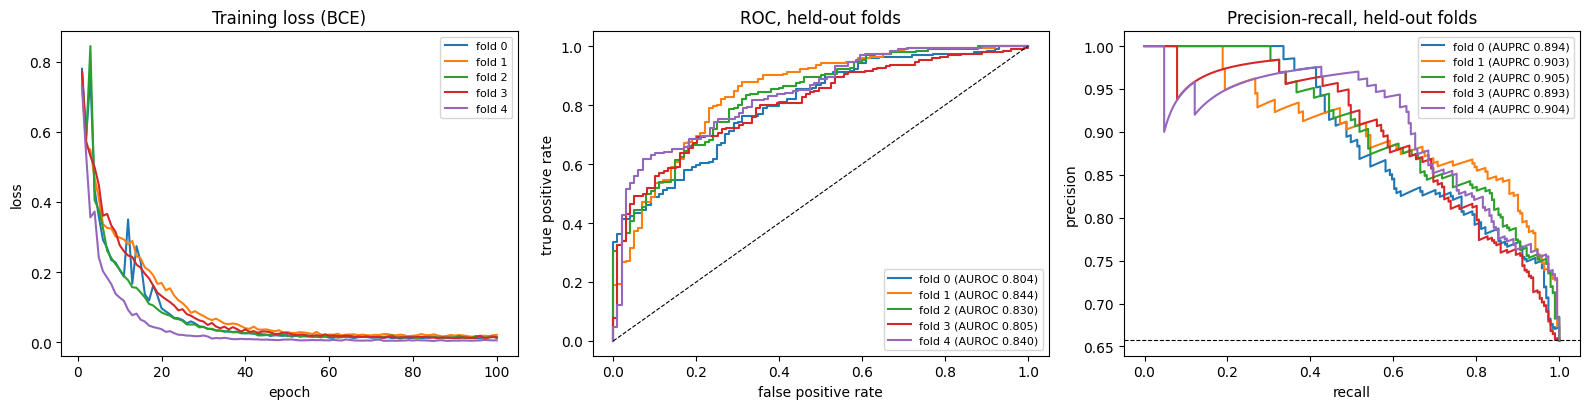

In [80]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

for i, hist in enumerate(cv["histories"]):
    axes[0].plot(hist["epoch"], hist["train_loss"], label=f"fold {i}")
axes[0].set(title="Training loss (BCE)", xlabel="epoch", ylabel="loss")
axes[0].legend(fontsize=8)

for i, (y, prob) in enumerate(cv["scores"]):
    fpr, tpr, _ = roc_curve(y, prob)
    axes[1].plot(fpr, tpr, label=f"fold {i} (AUROC {auc(fpr, tpr):.3f})")
    prec, rec, _ = precision_recall_curve(y, prob)
    axes[2].plot(rec, prec, label=f"fold {i} (AUPRC {auc(rec, prec):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].set(title="ROC, held-out folds", xlabel="false positive rate", ylabel="true positive rate")
axes[2].axhline(density, color="k", ls="--", lw=0.8)
axes[2].set(title="Precision-recall, held-out folds", xlabel="recall", ylabel="precision")
for ax in axes[1:]:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**How to compare with the paper.** The paper's Table 1 and 2 list AUROC/AUPRC for the *1000-gene* setting (for example mHSC-L: 0.842 / 0.840). The 500-gene results that match the example data in the repo are only shown graphically in Fig. 3, so a direct numeric comparison is only available if you run the matching dataset from the Zenodo archive cited in the paper (https://doi.org/10.5281/zenodo.3378975). Also expect fold-to-fold noise: results depend on the seed and on the random fold assignment.

## 10. Sanity baselines

*(Not in the paper or repo.)* On benchmarks built from a reference network with a few hub TFs, simple structural scores can already be strong, so it is worth seeing what the learned model has to beat. Three scorers, evaluated on exactly the same folds:

- `abs_pearson`: |Pearson correlation| of the two genes across cells (no labels used),
- `tf_out_degree`: how many training edges the TF has,
- `target_in_degree`: how many training edges point to the target.

The degree scorers use only *training* positives, so there is no leakage from the held-out fold.


NOT USED: Two simple stand-ins for the unsupervised competitors in Fig. 3:

* **Pearson**: score $(i,j)=|\mathrm{corr}(x_i,x_j)|$.
* **GENIE3-style**: for every target gene, an Extra-Trees regressor predicts its expression from the TFs; feature importance of TF $i$ is the score of $i\to j$ (the idea behind GENIE3, Huynh-Thu et al. 2010; this is a light re-implementation, not the original code).

Unsupervised scores need no training, so they are simply evaluated on each test fold and averaged.

In [85]:
def baseline_scores(expr_values, train_arr, test_arr):
    n = expr_values.shape[0]
    pos = train_arr[train_arr[:, 2] == 1]
    out_deg = np.bincount(pos[:, 0], minlength=n)
    in_deg = np.bincount(pos[:, 1], minlength=n)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        corr = np.abs(np.nan_to_num(np.corrcoef(expr_values)))
    return {"abs_pearson": corr[test_arr[:, 0], test_arr[:, 1]],
            "tf_out_degree": out_deg[test_arr[:, 0]].astype(float),
            "target_in_degree": in_deg[test_arr[:, 1]].astype(float)}


rows = []
for i in range(cfg.k_folds):
    train_a, test_a = np.vstack([f for j, f in enumerate(folds) if j != i]), folds[i]
    for name, s in baseline_scores(expr.values, train_a, test_a).items():
        auroc, auprc = auroc_auprc(test_a[:, 2], s)
        rows.append({"method": name, "fold": i, "AUROC": auroc, "AUPRC": auprc})
baselines = pd.DataFrame(rows).groupby("method")[["AUROC", "AUPRC"]].mean()
baselines.loc["IGEGRNS (this notebook)"] = cv["results"][["AUROC", "AUPRC"]].mean()
baselines.round(4)

,AUROC,AUPRC
method,,
abs_pearson,0.5450,0.6896
target_in_degree,0.4740,0.6384
tf_out_degree,0.8557,0.9152
IGEGRNS (this notebook),0.8245,0.8997


## 11. Ablations from paper Section 3.3

The paper varies the aggregator (mean / LSTM / max), removes Top-k pooling, replaces the 3-layer CNN by a single layer, and varies the embedding size (64 / 128 / 256 / 512). Each variant below is a `Config` tweak followed by a full CV. This is several times the cost of Step 8, so it is off by default. Set `RUN_ABLATIONS = True` to run it, and shrink the grid or `epochs` if you are on CPU. The `lstm` aggregator is the slowest.

In [86]:
RUN_ABLATIONS = False

ablation_grid = {
    "default (mean, k=1, 3-layer CNN, d=256)": {},
    "aggregator = max": {"aggregator": "max"},
    "aggregator = lstm": {"aggregator": "lstm"},
    "without Top-k pooling": {"topk": 0},
    "1-layer CNN": {"n_cnn_layers": 1},
    "embedding dim = 64": {"decode_dim": 64},
    "embedding dim = 128": {"decode_dim": 128},
    "embedding dim = 512": {"decode_dim": 512},
}

if RUN_ABLATIONS:
    ablation_rows = []
    for name, changes in ablation_grid.items():
        print(f"=== {name}")
        out = run_cv(replace(cfg, **changes), expr.values, folds, verbose=False)
        r = out["results"]
        ablation_rows.append({"variant": name, "AUROC": r["AUROC"].mean(), "AUPRC": r["AUPRC"].mean()})
        print(f"    AUROC {ablation_rows[-1]['AUROC']:.4f} | AUPRC {ablation_rows[-1]['AUPRC']:.4f}")
    ablation = pd.DataFrame(ablation_rows).set_index("variant")
    display(ablation.round(4))
else:
    print("RUN_ABLATIONS is False; flip it to reproduce the paper's ablation study.")

RUN_ABLATIONS is False; flip it to reproduce the paper's ablation study.


## 12. Export a ranked GRN

Cross-validation gives metrics; to *use* the model you score pairs and rank them. Below, the fold-0 model scores **every** candidate TF-target pair. Each pair is tagged with the fold it belonged to, so you can tell predictions on pairs the model was trained on from true held-out predictions (fold 0). The ranked table is saved to `outputs/predicted_grn_fold0.csv`.

In [97]:
fold_of = np.full((len(genes), len(genes)), -1)
for i, f in enumerate(folds):
    fold_of[f[:, 0], f[:, 1]] = i

art = cv["artifacts"][0]
all_pairs = torch.as_tensor(pairs, dtype=torch.long, device=device)
all_scores = torch.sigmoid(predict_logits(art["model"], x_all.to(device), art["mp_ei"].to(device),
                                         all_pairs, cfg.eval_batch_size)).cpu().numpy()

grn = pd.DataFrame({"TF": np.array(genes)[pairs[:, 0]],
                    "Target": np.array(genes)[pairs[:, 1]],
                    "score": all_scores,
                    "in_reference": labels,
                    "fold": fold_of[pairs[:, 0], pairs[:, 1]]})
grn["role"] = np.where(grn["fold"] == 0, "held-out", "seen in training")
grn = grn.sort_values("score", ascending=False).reset_index(drop=True)
grn.to_csv("predicted_grn_fold0.csv", index=False)

print("top held-out predictions:")
grn[grn["role"] == "held-out"].head(50)

top held-out predictions:


,TF,Target,score,in_reference,fold,role
729,MXI1,RSRP1,0.975409,1,0,held-out
737,MXI1,FKBP7,0.968781,1,0,held-out
745,ZEB1,FKBP7,0.961234,1,0,held-out
751,MXI1,SOD2,0.959659,1,0,held-out
757,MXI1,HILPDA,0.952417,1,0,held-out
759,ZEB1,SOD2,0.949226,1,0,held-out
764,CREB1,HELLS,0.937873,1,0,held-out
765,CREB1,FKBP7,0.933976,1,0,held-out
766,CREB1,CDK1,0.932680,1,0,held-out
767,CREB1,KIF23,0.924363,1,0,held-out


What does the above mean:

1. Index (729, 737, etc.): The row number from the original larger dataset.

2. TF (Transcription Factor): A protein (e.g., MXI1, ZEB1, CREB1) that binds to specific DNA sequences to control the rate of transcription of genetic information from DNA to messenger RNA.

3. Target: The specific gene (e.g., RSRP1, SOD2) being regulated by the transcription factor.

4. Score: A probability or confidence score generated by the algorithm (ranging here from ~0.90 to 0.97). This indicates how strongly the model believes the interaction between the TF and the Target gene is real.

5. in_reference: A binary flag where 1 means "True". This indicates that this specific interaction is already known and documented in a verified biological ground-truth database.

6. fold: Refers to the specific "fold" (iteration) of data used in k-fold cross-validation, a standard method for testing machine learning models.

7. role (held-out): Indicates that this chunk of data was deliberately hidden from the AI during its training phase. It was kept as a "held-out" test set to evaluate how accurately the model can predict interactions it has never seen before.

####The big picture: This data confirms that a computational biology model successfully and confidently (with >90% probability) identified known biological interactions (since in_reference = 1) on a test dataset it wasn't allowed to train on (held-out).

## 13. Running on your own data

Change `Config` and re-run from Step 3:

```python
cfg = Config(
    data_dir="path/to/folder",
    expr_file="my_expression.csv",
    ref_file="my_network.csv",
    genes_in_rows=False,       # True if the file is genes x cells; False if cells x genes
)
```

What the pipeline expects:

- **Expression file:** first column = row names (gene names if `genes_in_rows=True`, cell names otherwise). Gene names must be unique.
- **Reference network:** the first two columns are `TF, target` (any header, `Gene1/Gene2` or `gene1/gene2` both work). TFs are the distinct values of the first column and targets of the second, exactly as in the original. If your network contains genes that are absent from the expression matrix, those edges are dropped and a message is printed.
- **The candidate set is not "all gene pairs".** It is TFs × targets taken from the reference network, so the number of negatives depends on how many distinct TFs and targets the network has. If you want to restrict candidates (say, to a list of known TFs), filter `tfs` in Step 4.
- For a large gene set, set `train_batch_size` (for example `4096`) so that the CNN input tensor of shape `(pairs, k + 2, d)` does not have to fit in memory all at once. The shape-checking cells in Step 6 will tell you the size per pair.

## 14. Deviations from the repo, and caveats worth knowing

### Where this notebook differs from the repository

| Item | Paper | Repo (`Main.py`, `model.py`) | This notebook |
|---|---|---|---|
| Loss | BCE on sigmoid scores (Eq. 8) | `binary_cross_entropy_with_logits` applied to outputs that were **already passed through a sigmoid** (a double sigmoid) | BCE-with-logits on the raw logits, which is Eq. (8) |
| Learning rate | 0.01, ×0.8 every 10 epochs | 0.005, ×0.8 every 5 epochs, 100 epochs | repo values, configurable |
| `SAGEConv` arguments | mean aggregator, normalisation not specified | passes the aggregator and `normalize` positionally; the argument order differs between PyG releases, so on some versions the aggregator option may not take effect | keyword arguments (`aggr=`, `normalize=`) |
| FC input size | | `LazyLinear` inferred at first forward | computed analytically (663 for $d=256$, 3 blocks, $k=1$) |
| Edge tensor and pair construction | | Python loops over pairs and pandas lookups | vectorised; same tensors |
| Top-k ranking nonlinearity | ReLU (Eq. 3) | tanh (PyG) | tanh (PyG) |

**The double sigmoid matters for interpreting loss values.** In the repo, the model's output $s=\sigma(z)\in(0,1)$ is fed to a loss that applies a second sigmoid. The loss is then bounded below: even a perfect classifier cannot get under about $\ln(1+e^{-1})\approx0.31$ on positives and $\ln 2\approx0.69$ on negatives. Training losses printed by the original code are therefore high by construction, whatever the ranking quality. With the corrected loss, values near zero are possible, and loss values from the two versions should not be compared with each other.

### Caveats that apply to the method as published

1. **Training pairs are also graph edges.** The message-passing graph contains the training positives, and those same pairs are the positive training labels. The model can therefore partly "see" the answer for training positives, while held-out positives are never in the graph. This is how the original is built, so it is reproduced here, but it means training loss is optimistic compared with held-out performance, and the held-out fold is the right number to report.
2. **Negatives are "not in the reference network", not "known not to regulate".** With reference networks that are incomplete, some negatives are false negatives, which caps achievable precision.
3. **Degree structure.** In reference networks with hub TFs, a TF's out-degree and a target's in-degree can be predictive on their own (Step 10 measures this on your data). A learned model that exploits this is not necessarily learning regulatory logic.
4. **No model selection on the held-out fold.** The reported numbers come from the last epoch. If you add early stopping or hyperparameter tuning, use a separate validation split inside the training folds.
5. **Seed sensitivity.** Results vary with the seed and the fold assignment; report mean ± std over folds, and ideally over several seeds.
6. **PyG version differences.** The Step 6 checks compare hand-written GraphSAGE and Top-k pooling against `SAGEConv` and `TopKPooling` with `assert`s, so if your installed PyG version behaves differently from what is described here, those cells fail loudly instead of silently training a different model.

## Part 8: Inferred-network case study (Sec. 3.4, Fig. 5)

Protocol from the paper: restrict to the ~100 most variable genes, train on **20 % of the real directed edges plus an equal number of negatives**, then infer edges on the rest. Edge colours in Fig. 5: **red** = true edge predicted positive (TP), **green** = true edge predicted negative (FN), **blue** = non-edge predicted negative (TN). I additionally draw false positives in **orange**, which the paper's colouring omits. Node size and shade follow degree.

Here this is run on the first dataset (synthetic or real). With real data, use the MEF->myoblast and hESC->endoderm data from the paper with the regulatory-network references it cites.

To get a similar network you have to build the subnetwork from the full HepG2 reference (342,862 edges) and the full expression matrix raw, not from the 503-gene file. The cell below does that: it picks about 20 expressed, variable TFs, then about 80 variable genes they regulate, and uses the edges among those genes. It also draws only the held-out edges, with TFs as labelled hubs.

This cell needs raw, ref_all (columns Gene1/Gene2), fit_fold, to_edge_index and set_seed from earlier cells.

Things to adjust:

Too dense: ChIP-seq networks are dense among well-connected TFs. Lower N_TF to about 10–12, or lower N_TARGET.

Too sparse: Raise N_TF, or lower the >= 3 threshold on regulators per target.

Only the 4 original TFs: The 4 TFs came from the preprocessing cell, which only kept TFs in the top-1000 by variance. This cell avoids that by going back to raw. The CV results in Steps 8–10 are still based on those 4 TFs. If you want them on more TFs too, widen tf_pool in the preprocessing cell (for example to 5 * N_TOP) and re-run from there.



50 genes | 10 TFs | 240 true edges
held-out AUROC=0.716, AUPRC=0.728
{'TP': 101, 'FN': 91, 'TN': 154, 'FP': 38}


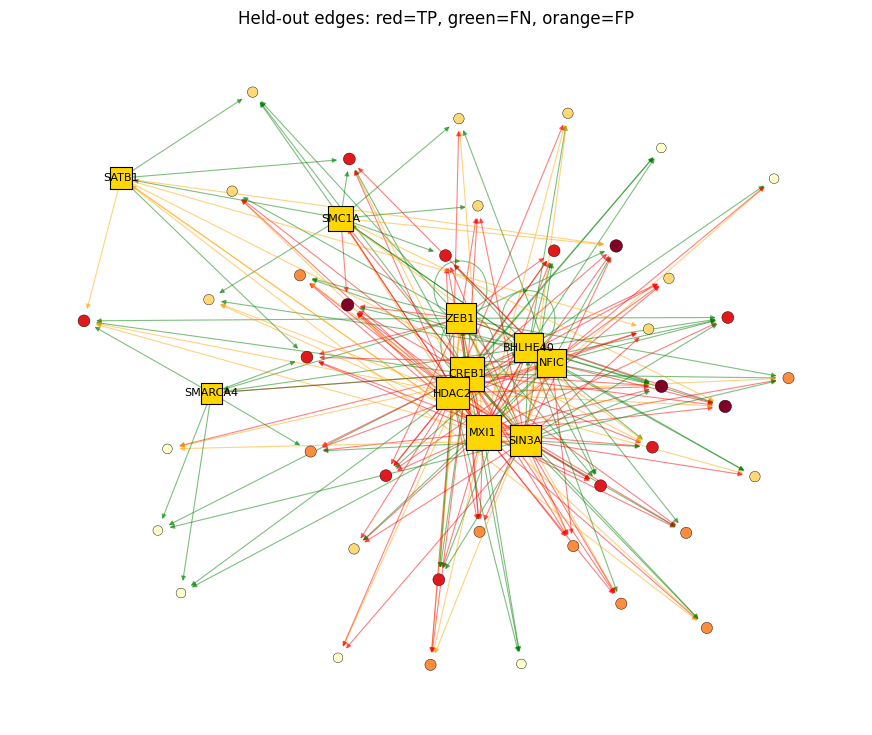

In [98]:
import networkx as nx

N_TF, N_TARGET = 10, 40      # lower N_TF (e.g. 12) if the graph is too dense
SHOW_TN = False              # True also draws sampled non-edges in blue

def build_case_subnetwork(raw, ref_all, n_tf=N_TF, n_target=N_TARGET, min_frac=0.2):
    # expressed genes only (non-zero in >= 20% of cells)
    expressed = raw.index[(raw > 0).mean(axis=1) >= min_frac]
    ref = ref_all[ref_all.Gene1.isin(expressed) & ref_all.Gene2.isin(expressed)].drop_duplicates()

    # TFs: well-connected in the reference, then the most variable of those
    deg = ref.groupby("Gene1").size().sort_values(ascending=False)
    cand_tf = deg.index[: 5 * n_tf]
    tfs = raw.loc[cand_tf].var(axis=1).sort_values(ascending=False).index[:n_tf]

    # targets: regulated by >= 3 of the chosen TFs, then the most variable
    sub = ref[ref.Gene1.isin(tfs)]
    tcount = sub[~sub.Gene2.isin(tfs)].groupby("Gene2").size()
    cand_t = tcount[tcount >= 3].index
    targets = raw.loc[cand_t].var(axis=1).sort_values(ascending=False).index[:n_target]

    genes = list(tfs) + list(targets)
    g2i = {g: i for i, g in enumerate(genes)}
    edges = ref[ref.Gene1.isin(tfs) & ref.Gene2.isin(genes)]
    pos = np.column_stack([edges.Gene1.map(g2i), edges.Gene2.map(g2i)]).astype(int)

    X = raw.loc[genes].values.astype(np.float32)
    X = (X - X.mean(1, keepdims=True)) / (X.std(1, keepdims=True) + 1e-8)   # z-score per gene
    return np.array(genes), X, pos, np.arange(len(tfs))

def case_study(cfg, raw, ref_all, train_frac=0.2, seed=6, thr=0.5):
    names, X, pos, tf_ids = build_case_subnetwork(raw, ref_all)
    n = len(names); rng = np.random.default_rng(seed)
    print(f"{n} genes | {len(tf_ids)} TFs | {len(pos)} true edges")

    perm = rng.permutation(len(pos)); n_tr = max(int(round(train_frac * len(pos))), 2)
    pos_tr, pos_te = pos[perm[:n_tr]], pos[perm[n_tr:]]
    posset = {tuple(e) for e in pos.tolist()}

    def sample_neg(k, exclude):
        out = set()
        while len(out) < k:
            i, j = int(rng.choice(tf_ids)), int(rng.integers(n))
            if i != j and (i, j) not in posset and (i, j) not in exclude:
                out.add((i, j))
        return np.array(sorted(out))

    neg_tr = sample_neg(len(pos_tr), set())
    neg_te = sample_neg(len(pos_te), {tuple(e) for e in neg_tr.tolist()})
    mk = lambda p, q: np.vstack([np.column_stack([p, np.ones(len(p), int)]),
                                 np.column_stack([q, np.zeros(len(q), int)])])
    train_arr, test_arr = mk(pos_tr, neg_tr), mk(pos_te, neg_te)

    set_seed(seed)
    _, _, prob, y = fit_fold(cfg, torch.tensor(X), to_edge_index(pos_tr),
                             train_arr, test_arr, verbose=False)
    return names, pos, tf_ids, test_arr, prob >= thr, auroc_auprc(y, prob)

names, pos, tf_ids, test_arr, pred, (auroc, auprc) = case_study(cfg, raw, ref_all)
pairs_te, y_te = test_arr[:, :2], test_arr[:, 2]
print(f"held-out AUROC={auroc:.3f}, AUPRC={auprc:.3f}")
print(dict(TP=int(((y_te==1)&pred).sum()), FN=int(((y_te==1)&~pred).sum()),
           TN=int(((y_te==0)&~pred).sum()), FP=int(((y_te==0)&pred).sum())))

# layout from the full true network so the structure is stable
Gfull = nx.Graph(); Gfull.add_nodes_from(range(len(names))); Gfull.add_edges_from(map(tuple, pos))
layout = nx.spring_layout(Gfull, seed=1, k=1.2 / np.sqrt(len(names)), iterations=300)

G = nx.DiGraph(); G.add_nodes_from(range(len(names)))
for (i, j), yt, p in zip(pairs_te, y_te, pred):
    if yt == 0 and not p and not SHOW_TN:
        continue
    c = "red" if (yt and p) else "green" if yt else "orange" if p else "dodgerblue"
    G.add_edge(int(i), int(j), c=c)

deg = np.array([G.degree(v) for v in G.nodes])
is_tf = np.isin(np.arange(len(names)), tf_ids)
plt.figure(figsize=(11, 9))
nx.draw_networkx_edges(G, layout, edge_color=[G[u][v]["c"] for u, v in G.edges],
                       alpha=0.5, arrows=True, arrowsize=7, width=0.8)
nx.draw_networkx_nodes(G, layout, nodelist=list(np.flatnonzero(~is_tf)),
                       node_size=25 + 8 * deg[~is_tf], node_color=deg[~is_tf],
                       cmap="YlOrRd", edgecolors="k", linewidths=0.3)
nx.draw_networkx_nodes(G, layout, nodelist=list(tf_ids), node_shape="s",
                       node_size=120 + 12 * deg[is_tf], node_color="gold",
                       edgecolors="k", linewidths=0.8)
nx.draw_networkx_labels(G, layout, {int(v): names[v] for v in tf_ids}, font_size=8)
plt.title("Held-out edges: red=TP, green=FN, orange=FP" + (", blue=TN" if SHOW_TN else ""))
plt.axis("off"); plt.show()

The nodes in the paper’s network are almost all TFs, around 45 per panel. It is a dense TF→TF network: 666 reference edges among about 46 TFs gives the stated sparsity of 0.31 (666 / (46 × 45)). That is also why it looks so dense, with every node linked to many others. In the paper’s recipe, “top 100 genes” means the 100 most variable genes among the TFs, and the reference network is restricted to edges between them. The cell above drew TF→gene edges, which produces stars.

The cell below reproduces that recipe, treating the TFs in HepG2 reference (the Gene1 column) as the TF list, since TFDB isn’t available here. It keeps the paper’s protocol: 20% of true edges plus an equal number of negatives for training, and the rest for testing. It draws the three paper colours (red = TP, green = FN, blue = TN) with all nodes labelled, and shades and sizes nodes by degree. It needs `raw`, `ref_all`, `cfg`, `fit_fold`, `to_edge_index`, `set_seed` and `auroc_auprc` from earlier cells.

50 TFs | 878 true edges | sparsity 0.36 (paper: 0.31 / 0.17)
held-out AUROC=0.827, AUPRC=0.824
{'TP': 496, 'FN': 206, 'TN': 555, 'FP': 147}


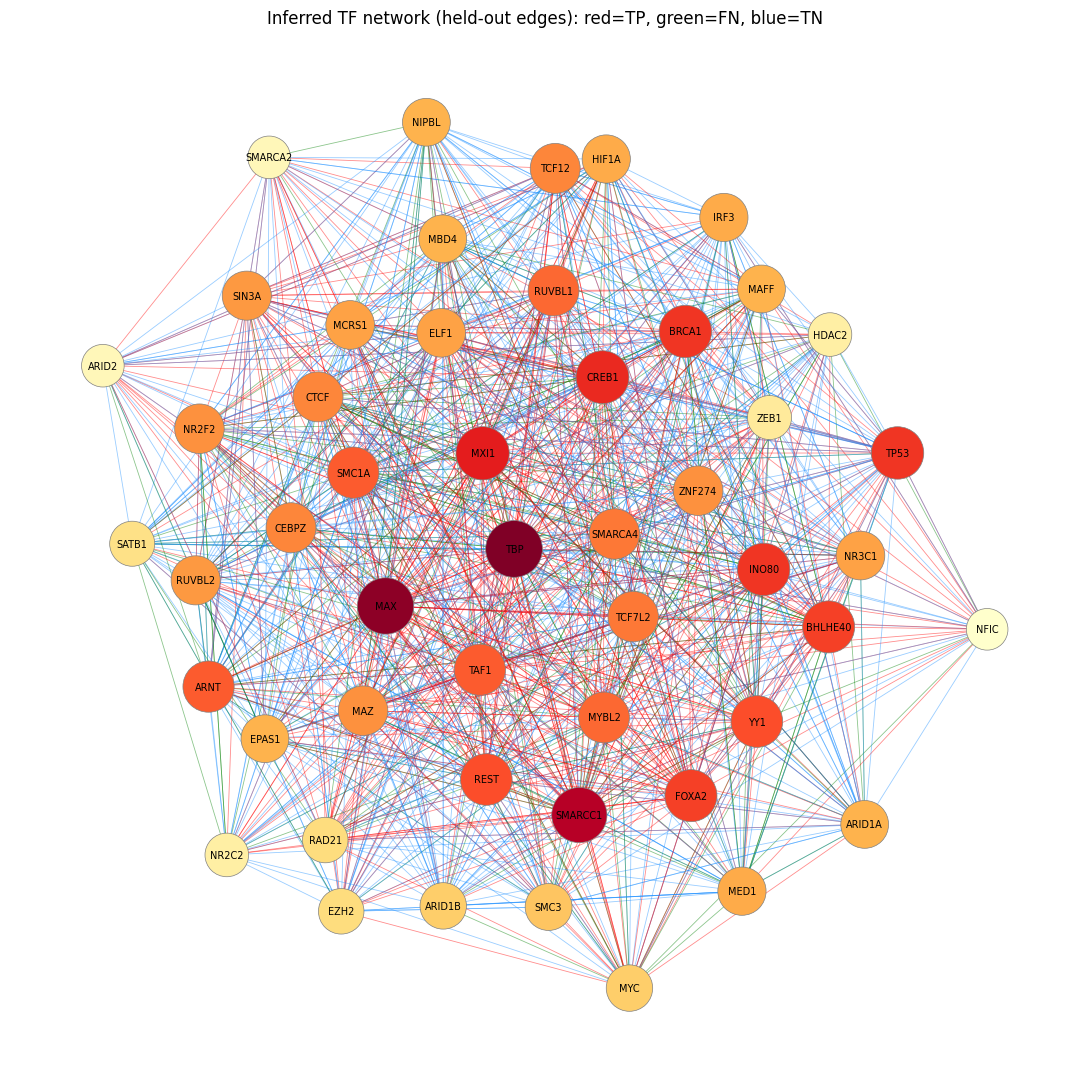

In [99]:
import networkx as nx

N_NODES   = 50          # paper's panels have ~45-50 TF nodes
LAYOUT    = "kk"        # "kk" (Kamada-Kawai), "spring", or "circle" (sorted by degree)
SHOW_FP   = False       # paper draws only red/green/blue; True adds orange false positives

def build_tf_subnetwork(raw, ref_all, n_nodes=N_NODES, min_frac=0.2):
    expressed = raw.index[(raw > 0).mean(axis=1) >= min_frac]
    ref = ref_all[["Gene1", "Gene2"]].drop_duplicates()
    ref = ref[ref.Gene1 != ref.Gene2]

    tf_set = sorted(set(ref.Gene1) & set(expressed))           # TFs = regulators in the reference
    genes = list(raw.loc[tf_set].var(axis=1).sort_values(ascending=False).index[:n_nodes])
    g2i = {g: i for i, g in enumerate(genes)}

    e = ref[ref.Gene1.isin(genes) & ref.Gene2.isin(genes)]      # TF -> TF edges only
    pos = np.column_stack([e.Gene1.map(g2i), e.Gene2.map(g2i)]).astype(int)

    X = raw.loc[genes].values.astype(np.float32)
    X = (X - X.mean(1, keepdims=True)) / (X.std(1, keepdims=True) + 1e-8)
    return np.array(genes), X, pos

def case_study(cfg, raw, ref_all, train_frac=0.2, seed=6, thr=0.5):
    names, X, pos = build_tf_subnetwork(raw, ref_all)
    n = len(names); rng = np.random.default_rng(seed)
    print(f"{n} TFs | {len(pos)} true edges | sparsity {len(pos) / (n * (n - 1)):.2f} (paper: 0.31 / 0.17)")

    perm = rng.permutation(len(pos)); n_tr = max(int(round(train_frac * len(pos))), 2)
    pos_tr, pos_te = pos[perm[:n_tr]], pos[perm[n_tr:]]

    posset = {tuple(e) for e in pos.tolist()}
    non_edges = np.array([(i, j) for i in range(n) for j in range(n)
                          if i != j and (i, j) not in posset])
    non_edges = non_edges[rng.permutation(len(non_edges))]
    neg_tr = non_edges[:len(pos_tr)]
    neg_te = non_edges[len(pos_tr):len(pos_tr) + len(pos_te)]    # equal-sized negatives

    mk = lambda p, q: np.vstack([np.column_stack([p, np.ones(len(p), int)]),
                                 np.column_stack([q, np.zeros(len(q), int)])])
    train_arr, test_arr = mk(pos_tr, neg_tr), mk(pos_te, neg_te)

    set_seed(seed)
    _, _, prob, y = fit_fold(cfg, torch.tensor(X), to_edge_index(pos_tr),
                             train_arr, test_arr, verbose=False)
    return names, test_arr, prob >= thr, auroc_auprc(y, prob)

names, test_arr, pred, (auroc, auprc) = case_study(cfg, raw, ref_all)
pairs_te, y_te = test_arr[:, :2], test_arr[:, 2]
print(f"held-out AUROC={auroc:.3f}, AUPRC={auprc:.3f}")
print(dict(TP=int(((y_te==1)&pred).sum()), FN=int(((y_te==1)&~pred).sum()),
           TN=int(((y_te==0)&~pred).sum()), FP=int(((y_te==0)&pred).sum())))

# ---- Fig. 5-style drawing ----
G = nx.DiGraph(); G.add_nodes_from(range(len(names)))
for (i, j), yt, p in zip(pairs_te, y_te, pred):
    if yt == 0 and p and not SHOW_FP:
        continue
    c = "red" if (yt and p) else "green" if yt else "orange" if p else "dodgerblue"
    G.add_edge(int(i), int(j), c=c)

deg = np.array([G.degree(v) for v in G.nodes], dtype=float)
U = G.to_undirected()
if LAYOUT == "kk":
    layout = nx.kamada_kawai_layout(U)
elif LAYOUT == "circle":
    order = list(np.argsort(-deg))
    layout = nx.circular_layout(U) if False else {int(v): (np.cos(2*np.pi*k/len(order)),
                                                          np.sin(2*np.pi*k/len(order)))
                                                 for k, v in enumerate(order)}
else:
    layout = nx.spring_layout(U, seed=0, k=1.5 / np.sqrt(len(names)), iterations=500)

plt.figure(figsize=(11, 11))
nx.draw_networkx_edges(G, layout, edge_color=[G[u][v]["c"] for u, v in G.edges],
                       alpha=0.45, arrows=True, arrowsize=6, width=0.6,
                       node_size=300)
nx.draw_networkx_nodes(G, layout, node_size=150 + 22 * deg, node_color=deg,
                       cmap="YlOrRd", edgecolors="gray", linewidths=0.5)
nx.draw_networkx_labels(G, layout, {i: names[i] for i in range(len(names))}, font_size=7)
plt.title("Inferred TF network (held-out edges): red=TP, green=FN, blue=TN")
plt.axis("off"); plt.tight_layout(); plt.show()

What to expect and tune:

Edge counts: The paper reports 244 red, 256 green and 256 blue edges. Your counts will differ, because the number of TF→TF edges depends on which TFs are in the top-variance set and on the HepG2 network. Tune N_NODES to match the paper’s density. A smaller value gives a sparser graph, and a larger one a denser graph.


Layout: The paper’s figure pushes high-degree TFs to the periphery. LAYOUT="kk" is the closest default. "circle" puts the nodes on a ring sorted by degree, which is easy to read when the graph is very dense.


Gene names: The paper’s panels are MEF→myoblast (mouse) and hESC→endoderm (human) with a different reference network. Your figure will show liver (HepG2) TFs instead of MYC/EBF1 or HAND1/TCF7. To reproduce those exact genes you would need the GSE75748 (hESC) expression data and the regulatory-network reference from regulatorynetworks.org.


Metrics. Don’t expect AUROC and AUPRC like the paper’s 0.67–0.74 and 0.45. They depend on this dataset.

## Part 9: Running on the real BEELINE data

1. Download the BEELINE data from Zenodo (DOI 10.5281/zenodo.3378975, linked in the paper's *Data availability* section) and the cell-type-specific reference networks used by BEELINE (ChIP-seq networks for hESC / mESC, etc.).
2. Fill in `BEELINE_PATHS` below with the expression and network CSV paths of each of the six datasets, e.g. hESC, hHEP, mESC, mHSC-E, mHSC-GM, mHSC-L.
3. Set `DATA_MODE = "beeline"` in Part 1, choose `N_TOP = 500` or `1000`, set `QUICK_MODE = False`, and **Restart & Run All**.

Format expected by `load_beeline_csv`: `ExpressionData.csv` with gene names in the first column and cells as columns; the network file has columns `Gene1` (regulator) and `Gene2` (target).

### Paper reference values (IGEGRNS, 1000 genes, Tables 1-2) for comparison

In [100]:
PAPER_1000 = pd.DataFrame({
    "hHEP": [0.863, 0.781], "mHSC-L": [0.842, 0.840], "mESC": [0.841, 0.733],
    "mHSC-E": [0.915, 0.936], "mHSC-GM": [0.915, 0.937], "hESC": [0.808, 0.521]},
    index=["AUROC", "AUPRC"])
PAPER_1000

# Example for real data (edit the paths, then switch DATA_MODE in Part 1 and re-run from Part 2):
# BEELINE_PATHS = {
#     "hESC":    ("BEELINE/hESC/ExpressionData.csv",    "BEELINE/hESC/hESC-ChIP-seq-network.csv"),
#     "hHEP":    ("BEELINE/hHEP/ExpressionData.csv",    "BEELINE/hHEP/HepG2-ChIP-seq-network.csv"),
#     "mESC":    ("BEELINE/mESC/ExpressionData.csv",    "BEELINE/mESC/mESC-ChIP-seq-network.csv"),
#     "mHSC-E":  ("BEELINE/mHSC-E/ExpressionData.csv",  "BEELINE/mHSC-E/mHSC-ChIP-seq-network.csv"),
#     "mHSC-GM": ("BEELINE/mHSC-GM/ExpressionData.csv", "BEELINE/mHSC-GM/mHSC-ChIP-seq-network.csv"),
#     "mHSC-L":  ("BEELINE/mHSC-L/ExpressionData.csv",  "BEELINE/mHSC-L/mHSC-ChIP-seq-network.csv"),
# }

,hHEP,mHSC-L,mESC,mHSC-E,mHSC-GM,hESC
AUROC,0.863,0.842,0.841,0.915,0.915,0.808
AUPRC,0.781,0.840,0.733,0.936,0.937,0.521


## Notes and known differences from the paper

* **Equation corrections:** Eq. 1 aggregates $h^{l-1}$ (each `SAGEConv` layer consumes the previous layer's output); Eq. 3 uses the sigmoid inside Top-k scoring.
* **Leakage control:** the message-passing graph for each fold contains only training positives. Because training positives are both edges of the graph and training labels, while test positives are not edges of the graph, there is a mild train/test asymmetry inherent to this design.
* **Top-k with $k=1$:** the single selected node is graph-global and identical for every pair, so $X'$ acts mainly as a learned global context vector (and as a regulariser, as the paper argues).
* **Not reproduced:** the seven other competing methods in Fig. 3 (DGRNs, DeepRIG, CNNC, GNE, GRNBoost2, PIDC, SCODE, DeepSEM). The GENIE3-style and Pearson baselines are simplified.
* **Unreported details** (epochs, batch size, negative sampling, CNN width, etc.) are marked **[assumption]** and are exposed in `Config` so they can be tuned.

### Your assignment


1. **Inner validation:** use a validation split within each training fold to choose epoch, learning rate, embedding dimension, and CNN architecture. Do not use outer test metrics for tuning.
2. **Ablate components:** remove graph topology, Top-k pooling, or CNN one at a time to establish which component contributes value. Also test an expression-only model and a topology-only model. This reveals which component contributes actual predictive value.
3. **Control leakage:** compare expression-only and topology-only models; consider masking each supervised positive edge from message passing when scoring that edge.
4. **Use more evaluation regimes:** edge-held-out, TF-held-out, and target-held-out splits answer different generalization questions.
5. **Handle label incompleteness:** reference-network non-edges are not guaranteed negatives. State this limitation and run sensitivity analyses.
6. **Repeat seeds:** repeat the complete training and evaluation process across multiple random seeds and independent datasets. Report mean and standard deviation / confidence intervals across seeds and folds.
7. **Match the paper for strict reproduction:** check the authors' implementation for exact preprocessing, Top-k tensor layout, CNN padding/pooling, optimizer settings, and negative-sampling policy. The notebook here is an independent educational implementation, not a guarantee of exact numerical replication.
8. **Scale carefully:** the paper uses 256-dimensional embeddings and 500/1000 selected genes. Tune on real data with a validation protocol.
10. **Interpret scores carefully:** model outputs are ranking scores, not calibrated causal probabilities; this model predicts edge existence, not activation/repression sign.
11. **Permutation controls:** shuffle expression profiles across genes or cells under carefully chosen null hypotheses, rerun training, and compare against the original performance. A large performance drop under an appropriate null supports the importance of the preserved expression structure.

### Evaluate your predictions
The following metrics are useful.
| Metric | What it measures |
|---|---|
| Precision | Fraction of predicted edges that are correct |
| Recall | Fraction of reference edges recovered |
| F1 score | Harmonic mean of precision and recall |
| AUROC |	How well scores rank true edges above non-edges |
| AUPRC	| Precision-recall performance, especially useful with many non-edges |
| Sign accuracy |	Fraction of correctly recovered edges with the right activation/repression sign |

For binary predictions:
$$
\mathrm{Precision}=\frac{TP}{TP+FP}
$$

$$
\mathrm{Recall}=\frac{TP}{TP+FN}
$$

$$
F_1=\frac{2PR}{P+R}
$$

Here, \(TP\) means correctly predicted edges, \(FP\) means incorrect edges, and \(FN\) means reference edges your algorithm missed.
For a ranked edge list, evaluate precision and recall at \(k\), where \(k\) is the number of top-ranked edges you retain. If you use all reference edges, for example, compare the algorithm's top predictions with the reference edges.

### The CNN can learn embedding-coordinate artifacts:
The edge classifier builds an input tensor:
$$
E_{ij}=[h_i;\,h_j;\,h_{\mathrm{top}}]
$$
and applies one-dimensional convolutions across the embedding dimension.
It introduces a modeling assumption: neighboring embedding coordinates have a meaningful local structure that a kernel of size two can exploit. Learned embedding coordinates are generally not ordered biological features, so this assumption needs empirical validation.

Useful alternatives to compare:
- Concatenation followed by an MLP.
- An MLP using $h_i$, $h_j$, $h_i\odot h_j$, and $|h_i-h_j|$.
- A bilinear decoder $h_i^\top W h_j$.
- A relation-aware decoder that explicitly models activation versus repression, if reliable signed labels are available.

Do not assume the CNN is superior simply because it is more elaborate. Evaluate it against simpler decoders on the same splits.

Even if your GNN accurately predicts edges in a reference network, that does not establish that the inferred edges are causal or that their regulatory direction is biologically correct.

The current model predicts whether an edge exists. It does not explicitly infer activation versus repression. To evaluate signed GRNs, you would need signed ground-truth labels and a compatible prediction head and loss function.

Also, if you have only one expression matrix and one reference network, the model's evaluation is limited to that dataset's candidate universe. It cannot by itself establish generalization to other cell types.

# Milestone 3 work (added)

Everything above this line is the starting notebook (I only added the "Answers" cell at the very top). The cells below are what I added to answer the "Your assignment" list in cell 66. Every experiment here is a list of runs (variant, split type, seed, fold) that gets cached in `outputs/*.pkl`, so re-running the notebook only redoes work that isn't finished yet. Nothing here uses the outer test fold to pick anything.

**Run time:** training all of these from scratch is roughly 500 model fits (about an hour on 6 CPU cores, several hours on a 1-2 core machine like free Colab). The finished runs are saved in `outputs/*.pkl` next to this notebook, and re-running loads them (you'll see `loaded N finished runs` lines) instead of retraining. Delete a `.pkl` to redo that experiment.

In [27]:
# (added) experiment toolkit for the "Your assignment" list. Reuses StackedCNN, build_edge_inputs, auroc_auprc,
# and to_edge_index from the cells above. Nothing above is changed.
from sklearn.metrics import precision_recall_fscore_support

# ---------- 1. a wider candidate universe (the original one only has 4 TFs) ----------
def build_universe(raw, ref_all, n_top=500, tf_mult=10):
    """Same recipe as the preprocessing cell (top-variance genes + reference TFs in the top tf_mult*n_top), z-scored."""
    var = raw.var(axis=1).sort_values(ascending=False)
    keep = list(dict.fromkeys(list(var.index[:n_top]) + sorted(set(ref_all["Gene1"]) & set(var.index[:tf_mult * n_top]))))
    sub = raw.loc[keep]
    sub = sub[sub.std(axis=1) > 0]
    sub = sub.sub(sub.mean(axis=1), axis=0).div(sub.std(axis=1), axis=0)
    ref_u = load_reference_network_quiet(ref_all, set(sub.index))
    genes_u, tfs_u, targets_u, pairs_u, labels_u = build_candidate_pairs(sub, ref_u)
    return sub, ref_u, genes_u, tfs_u, targets_u, pairs_u, labels_u

def load_reference_network_quiet(ref_all, genes):
    r = ref_all[["Gene1", "Gene2"]].astype(str).drop_duplicates()
    r.columns = ["gene1", "gene2"]
    return r[r["gene1"].isin(genes) & r["gene2"].isin(genes)].reset_index(drop=True)

# ---------- 2. splits: edge-held-out, TF-held-out, target-held-out ----------
def split_arr(arr, regime, k, seed):
    """arr: (n, 3) [tf, target, label]. Returns k arrays. regime: 'edge' | 'tf' | 'target'."""
    rng = np.random.default_rng(seed)
    if regime == "edge":                                   # stratified, like make_folds
        pos, neg = arr[arr[:, 2] == 1], arr[arr[:, 2] == 0]
        pos, neg = pos[rng.permutation(len(pos))], neg[rng.permutation(len(neg))]
        return [np.vstack(z) for z in zip(np.array_split(pos, k), np.array_split(neg, k))]
    col = 0 if regime == "tf" else 1
    groups = rng.permutation(np.unique(arr[:, col]))
    which = {g: i % k for i, g in enumerate(groups)}      # each TF (or target) lands in exactly one fold
    f = np.array([which[g] for g in arr[:, col]])
    return [arr[f == i] for i in range(k)]

def outer_folds(pairs, labels, regime, k, seed):
    return split_arr(np.column_stack([pairs, labels]), regime, k, seed)

def train_test(folds, i):
    return np.vstack([f for j, f in enumerate(folds) if j != i]), folds[i]

def inner_split(train_arr, regime, seed, k=5):
    """Validation split INSIDE a training fold (same regime), so the outer test fold is never used for tuning."""
    parts = split_arr(train_arr, regime, k, seed + 1000)
    return np.vstack(parts[1:]), parts[0]                  # (fit, validation)

# ---------- 3. metrics ----------
def metrics(y, p):
    y = np.asarray(y); p = np.asarray(p)
    if y.min() == y.max():
        return dict(AUROC=np.nan, AUPRC=np.nan, P_at_k=np.nan, F1_at_05=np.nan, P_at_05=np.nan, R_at_05=np.nan, base=y.mean())
    auroc, auprc = auroc_auprc(y, p)
    k = int(y.sum()); top = np.argsort(-p)[:k]
    pr, rc, f1, _ = precision_recall_fscore_support(y, (p >= 0.5).astype(int), average="binary", zero_division=0)
    return dict(AUROC=auroc, AUPRC=auprc, P_at_k=y[top].mean(), P_at_05=pr, R_at_05=rc, F1_at_05=f1, base=y.mean())

# ---------- 4. a configurable model (graph / topk / decoder switches) ----------
class Net(nn.Module):
    def __init__(self, in_dim, d=256, topk=1, decoder="cnn", n_cnn=3, dropout=0.5):
        super().__init__()
        self.decoder = decoder
        self.encoder = SAGEConv(in_dim, d, aggr="mean", normalize=True)
        use_pool = decoder == "cnn" and topk > 0
        self.pool = TopKPooling(d, ratio=topk) if use_pool else None
        if decoder == "cnn":
            self.dec = StackedCNN(channels=(topk if use_pool else 0) + 2, length=d, n_layers=n_cnn, dropout=dropout)
        elif decoder in ("mlp", "mlp4"):
            self.dec = nn.Sequential(nn.Linear((2 if decoder == "mlp" else 4) * d, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, 1))
        elif decoder == "bilinear":
            self.dec = nn.Bilinear(d, d, 1)
        else:
            raise ValueError(decoder)

    def embed(self, x, ei):
        h = F.relu(self.encoder(x, ei))
        top = self.pool(h, ei)[0] if self.pool is not None else h.new_zeros(0, h.size(1))
        return h, top

    def score(self, h, top, pairs):
        hi, hj = h[pairs[:, 0]], h[pairs[:, 1]]
        if self.decoder == "cnn":
            return self.dec(build_edge_inputs(h, top, pairs))
        if self.decoder == "mlp":
            return self.dec(torch.cat([hi, hj], 1)).view(-1)
        if self.decoder == "mlp4":
            return self.dec(torch.cat([hi, hj, hi * hj, (hi - hj).abs()], 1)).view(-1)
        return self.dec(hi, hj).view(-1)

def degree_features(ei, n):
    deg_in = torch.zeros(n).index_add_(0, ei[1], torch.ones(ei.size(1)))
    deg_out = torch.zeros(n).index_add_(0, ei[0], torch.ones(ei.size(1)))
    f = torch.log1p(torch.stack([deg_in, deg_out], 1))
    return (f - f.mean(0)) / (f.std(0) + 1e-6)

def seed_everything(seed):                      # like set_seed above, minus the cudnn flags (those cannot be pickled for the workers)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

def train_eval(train_arr, test_arr, x, val_arr=None, *, graph="train", feat="expr", d=256, topk=1, decoder="cnn", n_cnn=3,
               lr=0.005, epochs=60, mask=False, perm=None, seed=0, eval_every=5, lr_step=5, gamma=0.8, dropout=0.5):
    """Train on train_arr (graph = its positives), evaluate val/test every eval_every epochs (test only reported, never used to pick).
    graph: 'train' | 'none'  (none = expression-only, no message passing)
    feat : 'expr' | 'topo'   (topo = only in/out-degree of the training graph, no expression)
    mask : each epoch only half of the training positives are in the graph and the OTHER half are the positive labels
    perm : None | 'genes' (shuffle which gene gets which expression row) | 'cells' (shuffle each gene's values across cells)"""
    seed_everything(seed)
    n = x.size(0)
    if perm == "genes":
        x = x[torch.randperm(n)]
    elif perm == "cells":
        x = torch.gather(x, 1, torch.argsort(torch.rand_like(x), dim=1))
    pos = torch.as_tensor(train_arr[train_arr[:, 2] == 1][:, :2], dtype=torch.long)
    neg = torch.as_tensor(train_arr[train_arr[:, 2] == 0][:, :2], dtype=torch.long)
    full_ei = to_edge_index(pos.numpy()) if graph == "train" else torch.zeros(2, 0, dtype=torch.long)
    xin = degree_features(to_edge_index(pos.numpy()), n) if feat == "topo" else x
    model = Net(xin.size(1), d, topk, decoder, n_cnn, dropout)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sch = torch.optim.lr_scheduler.StepLR(opt, step_size=lr_step, gamma=gamma)
    T = lambda a: torch.as_tensor(a[:, :2], dtype=torch.long)
    sets = {"test": test_arr}
    if val_arr is not None:
        sets["val"] = val_arr
    hist = []
    for ep in range(1, epochs + 1):
        model.train()
        if mask and graph == "train":
            perm_i = torch.randperm(len(pos)); half = len(pos) // 2
            ei, sup_pos = to_edge_index(pos[perm_i[:half]].numpy()), pos[perm_i[half:]]
        else:
            ei, sup_pos = full_ei, pos
        pairs_t = torch.cat([sup_pos, neg]); y = torch.cat([torch.ones(len(sup_pos)), torch.zeros(len(neg))])
        opt.zero_grad()
        h, top = model.embed(xin, ei)
        loss = F.binary_cross_entropy_with_logits(model.score(h, top, pairs_t), y)
        loss.backward(); opt.step(); sch.step()
        if ep % eval_every == 0 or ep == epochs:
            rec = {"epoch": ep, "train_loss": loss.item()}
            model.eval()
            with torch.no_grad():
                h, top = model.embed(xin, full_ei)
                for name, arr in sets.items():
                    p = torch.sigmoid(model.score(h, top, T(arr))).numpy()
                    for kk, v in metrics(arr[:, 2], p).items():
                        rec[f"{name}_{kk}"] = v
            hist.append(rec)
    return pd.DataFrame(hist)

def pick(hist, by="val_AUPRC"):
    """Row of the history at the epoch with the best VALIDATION score (falls back to the last epoch if no validation set)."""
    return hist.loc[hist[by].idxmax()] if by in hist else hist.iloc[-1]

## Wider candidate universe + job runner (added)

The original candidate-pair cell only has **4 TFs** (see its output), which makes a TF-held-out split basically meaningless and lets a "how many edges does this TF have" score do really well. So below I rebuild the universe with the same recipe as the preprocessing cell but a wider TF pool (`tf_pool = 10 * N_TOP` instead of `2 * N_TOP`, which is what the note in cell 15 suggests). Same repo rule for labels: every TF x target pair that isn't in the reference is a negative.

In [28]:
# (added) wider universe + a small parallel job runner. Every experiment below is a list of jobs (variant, regime, seed, fold).
import pickle, warnings
warnings.filterwarnings("ignore", message="A worker stopped")   # joblib noise when a worker is recycled
from joblib import Parallel, delayed

N_TOP_U, TF_MULT = 500, 10                     # same recipe as the preprocessing cell, but tf_pool = 10 * N_TOP instead of 2 * N_TOP
sub_u, ref_u, genes_u, tfs_u, targets_u, pairs_u, labels_u = build_universe(raw, ref_all, N_TOP_U, TF_MULT)
x_u = torch.tensor(sub_u.values, dtype=torch.float32)
x_raw_u = torch.tensor(raw.loc[sub_u.index].values, dtype=torch.float32)   # same genes, NOT z-scored (the repo feeds raw values)
print(f"wide universe: {sub_u.shape[0]} genes x {sub_u.shape[1]} cells | {len(tfs_u)} TFs | {len(targets_u)} targets | "
      f"{len(pairs_u)} candidate pairs | {int(labels_u.sum())} positives | positive fraction {labels_u.mean():.3f}")
print(f"(for comparison, the original universe in the candidate-pair cell had {len(tfs)} TFs and {len(pairs_all)} pairs)")

SEEDS = [0, 1, 2]                              # complete repeat per seed: new fold assignment + new initialisation
N_JOBS = max(1, min(6, (os.cpu_count() or 2) - 1))   # a few workers: each one holds its own copy of torch
EPOCHS = 60                                    # max epochs; the epoch actually used is chosen on the validation split
FULL = dict()                                  # the paper's model: mean SAGE (d=256) -> Top-k(1) -> 3-block CNN, lr 0.005

def degree_matched_negatives(pairs, labels, seed):
    """Draw as many negatives as positives with prob ~ outdeg(TF) * indeg(target) among the positives (cell 13's suggestion)."""
    rng = np.random.default_rng(seed)
    pos = pairs[labels == 1]; neg_idx = np.flatnonzero(labels == 0)
    n = pairs.max() + 1
    out_deg = np.bincount(pos[:, 0], minlength=n); in_deg = np.bincount(pos[:, 1], minlength=n)
    w = (out_deg[pairs[neg_idx, 0]] * in_deg[pairs[neg_idx, 1]]).astype(float) + 1e-9
    pick_i = rng.choice(neg_idx, size=len(pos), replace=False, p=w / w.sum())
    keep = np.sort(np.concatenate([np.flatnonzero(labels == 1), pick_i]))
    return pairs[keep], labels[keep]

def one_job(spec, x, pairs, labels):
    torch.set_num_threads(1)
    kw = dict(spec.get("kw", {}))
    if spec.get("neg") == "ratio1":
        pairs, labels = subsample_negatives(pairs, labels, 1.0, spec["seed"])
    elif spec.get("neg") == "degree":
        pairs, labels = degree_matched_negatives(pairs, labels, spec["seed"])
    if spec.get("raw_x"):
        x = x_raw_u
    folds = outer_folds(pairs, labels, spec["regime"], 5, spec["seed"])
    tr, te = train_test(folds, spec["fold"])
    if spec.get("hide", 0) > 0:                # pretend some known positives were never labelled (they become negatives, and leave the graph)
        rng = np.random.default_rng(spec["seed"] + 7)
        posi = np.flatnonzero(tr[:, 2] == 1)
        tr = tr.copy(); tr[rng.choice(posi, int(spec["hide"] * len(posi)), replace=False), 2] = 0
    fit, val = inner_split(tr, spec["regime"], spec["seed"])
    hist = train_eval(fit, te, x, val, epochs=spec.get("epochs", EPOCHS), seed=spec["seed"], **kw)
    best, last = pick(hist), hist.iloc[-1]
    row = {k: v for k, v in spec.items() if k != "kw"}
    row.update({f"kw_{k}": v for k, v in kw.items()})
    row.update(epoch_sel=int(best["epoch"]), val_AUPRC=best["val_AUPRC"], n_test=len(te), test_pos=int(te[:, 2].sum()))
    for m in ["AUROC", "AUPRC", "P_at_k", "P_at_05", "R_at_05", "F1_at_05", "base"]:
        row[f"sel_{m}"], row[f"last_{m}"] = best[f"test_{m}"], last[f"test_{m}"]
    return row, hist.assign(**{k: str(v) for k, v in spec.items() if k not in ("kw",)})

def run_jobs(specs, tag, x=None, pairs=None, labels=None, reuse=True):
    """Run specs in parallel; cached in outputs/<tag>.pkl so a re-run of the notebook does not repeat finished work."""
    f = OUT_DIR / f"{tag}.pkl"
    if reuse and f.exists():
        rows, hists = pickle.load(open(f, "rb"))
        if len(rows) == len(specs):
            print(f"[{tag}] loaded {len(rows)} finished runs from {f}")
            return pd.DataFrame(rows), pd.concat(hists, ignore_index=True)
    x = x_u if x is None else x; pairs = pairs_u if pairs is None else pairs; labels = labels_u if labels is None else labels
    t0 = time.time()
    out = Parallel(n_jobs=N_JOBS)(delayed(one_job)(s, x, pairs, labels) for s in specs)
    rows, hists = [o[0] for o in out], [o[1] for o in out]
    pickle.dump((rows, hists), open(f, "wb"))
    print(f"[{tag}] {len(rows)} runs in {(time.time() - t0) / 60:.1f} min on {N_JOBS} workers")
    return pd.DataFrame(rows), pd.concat(hists, ignore_index=True)

def make_specs(variants, regimes=("edge",), seeds=SEEDS, **common):
    return [dict(variant=v, regime=r, seed=s, fold=k, kw=kw, **common)
            for v, kw in variants.items() for r in regimes for s in seeds for k in range(5)]

def summarize(df, by, cols=("AUROC", "AUPRC", "P_at_k"), prefix="sel"):
    """Mean over the 5 folds first, then mean +/- std over seeds (so the std is 'seed-to-seed', not fold-to-fold noise)."""
    g = df.groupby(by + ["seed"])[[f"{prefix}_{c}" for c in cols]].mean().reset_index()
    out = g.groupby(by)[[f"{prefix}_{c}" for c in cols]].agg(["mean", "std"])
    out.columns = [f"{a.replace(prefix + '_', '')} {b}" for a, b in out.columns]
    return out.round(3)

wide universe: 535 genes x 465 cells | 34 TFs | 451 targets | 15334 candidate pairs | 5073 positives | positive fraction 0.331
(for comparison, the original universe in the candidate-pair cell had 4 TFs and 1452 pairs)


## 1. Inner validation (added)

For each outer training fold I hold out 20% of its pairs as a validation split, train 12 configs (3 learning rates x 2 embedding sizes x 1 or 3 CNN blocks), and pick the config **and** the epoch on validation AUPRC. The outer test fold only gets scored at the chosen epoch.

[hp_grid] loaded 60 finished runs from outputs/hp_grid.pkl


,chosen config,chosen epoch,val AUPRC,test AUPRC (chosen),"test AUPRC (default, val-epoch)","test AUPRC (default, last epoch)"
fold,,,,,,
0,lr=0.005 d=64 cnn=1,60,0.855,0.850,0.840,0.840
1,lr=0.001 d=256 cnn=1,60,0.837,0.817,0.814,0.814
2,lr=0.005 d=64 cnn=1,60,0.847,0.833,0.823,0.823
3,lr=0.001 d=256 cnn=1,60,0.827,0.824,0.819,0.819
4,lr=0.005 d=64 cnn=1,60,0.827,0.853,0.842,0.842


mean test AUPRC over the 5 outer folds -> tuned: 0.835 | default config at val-chosen epoch: 0.828 | default config at the last epoch (60): 0.828


,val AUPRC (used to pick),test AUPRC,test AUROC,mean chosen epoch
variant,,,,
lr=0.005 d=64 cnn=1,0.837,0.834,0.893,60.0
lr=0.001 d=256 cnn=1,0.834,0.832,0.893,60.0
lr=0.001 d=256 cnn=3,0.833,0.833,0.894,56.0
lr=0.005 d=256 cnn=1,0.832,0.828,0.891,60.0
lr=0.01 d=64 cnn=1,0.830,0.826,0.889,60.0
lr=0.005 d=256 cnn=3,0.828,0.828,0.891,60.0
lr=0.005 d=64 cnn=3,0.828,0.827,0.887,59.0
lr=0.01 d=256 cnn=1,0.824,0.819,0.887,60.0
lr=0.01 d=64 cnn=3,0.824,0.820,0.883,60.0


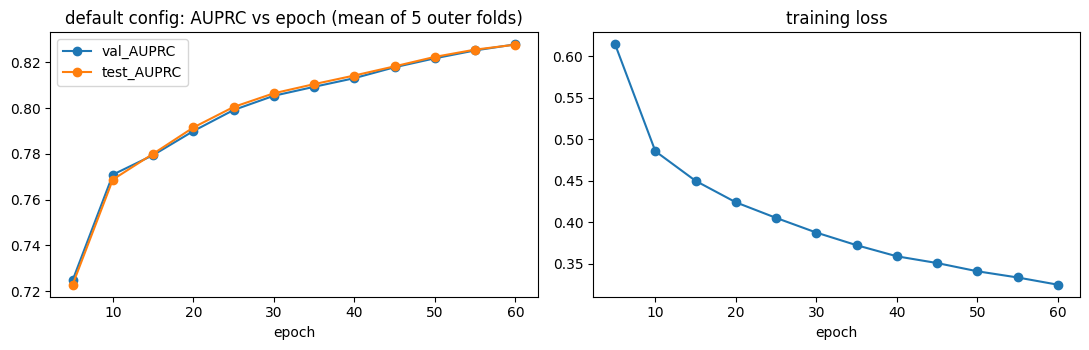

In [29]:
# Inner validation: for every OUTER training fold, the config (lr, embedding dim, CNN depth) and the epoch are picked on a validation
# split carved out of that training fold. The outer test fold is only looked at once, after the choice is made.
HP = {f"lr={lr} d={d} cnn={c}": dict(lr=lr, d=d, n_cnn=c) for lr in (0.001, 0.005, 0.01) for d in (64, 256) for c in (1, 3)}
hp, hp_hist = run_jobs(make_specs(HP, seeds=[0]), "hp_grid")

DEFAULT = "lr=0.005 d=256 cnn=3"                                   # the notebook's / paper's setting
chosen = hp.loc[hp.groupby("fold").val_AUPRC.idxmax()].set_index("fold")      # picked on the validation column ONLY
dflt = hp[hp.variant == DEFAULT].set_index("fold")
pick_tab = pd.DataFrame({"chosen config": chosen.variant, "chosen epoch": chosen.epoch_sel, "val AUPRC": chosen.val_AUPRC.round(3),
                         "test AUPRC (chosen)": chosen.sel_AUPRC.round(3), "test AUPRC (default, val-epoch)": dflt.sel_AUPRC.round(3),
                         "test AUPRC (default, last epoch)": dflt.last_AUPRC.round(3)})
display(pick_tab)
print("mean test AUPRC over the 5 outer folds -> tuned:", round(chosen.sel_AUPRC.mean(), 3), "| default config at val-chosen epoch:",
      round(dflt.sel_AUPRC.mean(), 3), "| default config at the last epoch (60):", round(dflt.last_AUPRC.mean(), 3))
cfg_tab = hp.groupby("variant")[["val_AUPRC", "sel_AUPRC", "sel_AUROC", "epoch_sel"]].mean().round(3).sort_values("val_AUPRC", ascending=False)
cfg_tab.columns = ["val AUPRC (used to pick)", "test AUPRC", "test AUROC", "mean chosen epoch"]
display(cfg_tab)

h = hp_hist[hp_hist.variant == DEFAULT].groupby("epoch")[["val_AUPRC", "test_AUPRC", "train_loss"]].mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
h[["val_AUPRC", "test_AUPRC"]].plot(ax=ax[0], marker="o"); ax[0].set(title="default config: AUPRC vs epoch (mean of 5 outer folds)", xlabel="epoch")
h["train_loss"].plot(ax=ax[1], marker="o"); ax[1].set(title="training loss", xlabel="epoch")
plt.tight_layout(); plt.show()

### Is the epoch cap binding? (added)

[epochs200] loaded 5 finished runs from outputs/epochs200.pkl
mean validation AUPRC peaks at epoch 190; the test AUPRC at that epoch is 0.835 (epoch 60: 0.828, epoch 200: 0.835)
epoch picked per outer fold by validation AUPRC: [185, 180, 200, 190, 75] | test AUPRC at those epochs: [0.844, 0.827, 0.831, 0.822, 0.848]


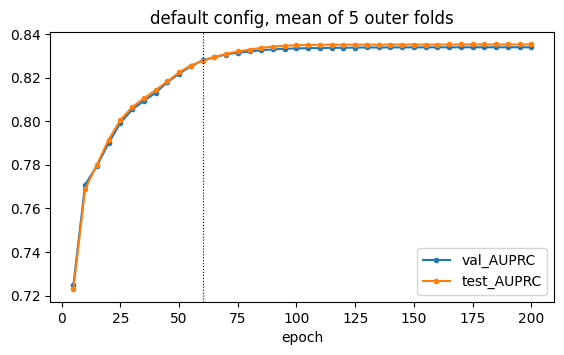

In [30]:
# Is 60 epochs enough? In the table above the chosen epoch is almost always the last one (60), so the cap is binding and "epoch" was not
# really chosen. Same default config, seed 0, 5 outer folds, but up to 200 epochs.
ep_specs = [dict(s, epochs=200) for s in make_specs({"default config, up to 200 epochs": dict()}, seeds=[0])]
ep_rows, ep_hist = run_jobs(ep_specs, "epochs200")
curve = ep_hist.groupby("epoch")[["val_AUPRC", "test_AUPRC", "val_AUROC", "test_AUROC"]].mean()
best_ep = curve.val_AUPRC.idxmax()
print(f"mean validation AUPRC peaks at epoch {best_ep}; the test AUPRC at that epoch is {curve.loc[best_ep, 'test_AUPRC']:.3f} "
      f"(epoch 60: {curve.loc[60, 'test_AUPRC']:.3f}, epoch 200: {curve.loc[200, 'test_AUPRC']:.3f})")
print("epoch picked per outer fold by validation AUPRC:", ep_rows.epoch_sel.tolist(), "| test AUPRC at those epochs:", ep_rows.sel_AUPRC.round(3).tolist())
curve[["val_AUPRC", "test_AUPRC"]].plot(figsize=(6.5, 3.5), marker=".", title="default config, mean of 5 outer folds"); plt.axvline(60, color="k", ls=":", lw=0.8); plt.show()

## 2-3. Ablations and leakage controls (added)

One piece removed at a time (topology, Top-k, CNN depth), plus an expression-only model, a topology-only model (just in/out-degree of the training graph, no expression), three simpler decoders from cell 68, and edge-masked training (each epoch half the training positives are in the graph and the *other* half are the labels, so no edge is scored while it sits in the graph). Also the three no-training scores from cell 50.

[ablations] loaded 135 finished runs from outputs/ablations.pkl


edge-held-out, 3 seeds x 5 folds (mean and std over seeds). A random scorer gets AUPRC = 0.331.


,AUROC mean,AUROC std,AUPRC mean,AUPRC std,P_at_k mean,P_at_k std
variant,,,,,,
full (paper model),0.884,0.009,0.817,0.017,0.738,0.012
no topology (expression only),0.874,0.004,0.794,0.008,0.714,0.008
"topology only (degrees, no expression)",0.870,0.007,0.783,0.003,0.720,0.012
no Top-k pooling,0.861,0.024,0.795,0.027,0.715,0.020
1-block CNN,0.889,0.002,0.827,0.003,0.745,0.000
"MLP on [h_i, h_j]",0.873,0.007,0.760,0.007,0.734,0.006
"MLP on [h_i, h_j, h_i*h_j, |h_i-h_j|]",0.881,0.001,0.786,0.008,0.741,0.000
bilinear h_i' W h_j,0.895,0.002,0.835,0.003,0.751,0.002
edge-masked training (leakage control),0.869,0.002,0.783,0.006,0.717,0.006


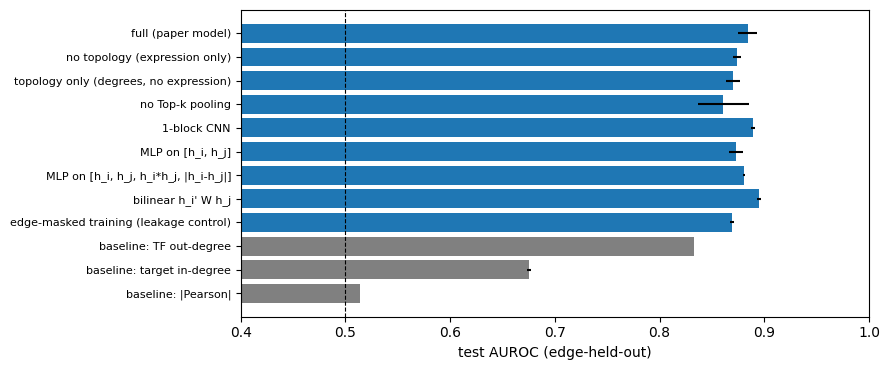

In [31]:
# Ablations (one thing removed at a time) + simpler decoders + leakage control. All on the edge-held-out folds of the wide universe,
# 3 seeds x 5 folds. Every variant uses the same inner-validation epoch rule, so they are compared fairly.
ABL = {
    "full (paper model)":                      dict(),
    "no topology (expression only)":           dict(graph="none"),
    "topology only (degrees, no expression)":  dict(feat="topo"),
    "no Top-k pooling":                        dict(topk=0),
    "1-block CNN":                             dict(n_cnn=1),
    "MLP on [h_i, h_j]":                       dict(decoder="mlp", topk=0),
    "MLP on [h_i, h_j, h_i*h_j, |h_i-h_j|]":   dict(decoder="mlp4", topk=0),
    "bilinear h_i' W h_j":                     dict(decoder="bilinear", topk=0),
    "edge-masked training (leakage control)":  dict(mask=True),
}
abl, abl_hist = run_jobs(make_specs(ABL), "ablations")

def baseline_rows(regime):
    """Scores that need no training: TF out-degree and target in-degree (from the TRAINING positives only) and |Pearson|."""
    pear = np.abs(np.nan_to_num(np.corrcoef(sub_u.values))); n = len(genes_u); rows = []
    for seed in SEEDS:
        folds = outer_folds(pairs_u, labels_u, regime, 5, seed)
        for k in range(5):
            tr, te = train_test(folds, k); pos = tr[tr[:, 2] == 1]
            od, idg = np.bincount(pos[:, 0], minlength=n), np.bincount(pos[:, 1], minlength=n)
            for name, s in {"baseline: TF out-degree": od[te[:, 0]], "baseline: target in-degree": idg[te[:, 1]],
                            "baseline: |Pearson|": pear[te[:, 0], te[:, 1]]}.items():
                m = metrics(te[:, 2], s.astype(float))
                if np.ptp(s) == 0:                  # constant score (e.g. a held-out TF has out-degree 0): no information, so AUPRC = base rate
                    m["AUPRC"], m["P_at_k"] = m["base"], m["base"]
                rows.append(dict(variant=name, regime=regime, seed=seed, fold=k, sel_AUROC=m["AUROC"], sel_AUPRC=m["AUPRC"], sel_P_at_k=m["P_at_k"]))
    return pd.DataFrame(rows)

base_edge = baseline_rows("edge")
tab = summarize(pd.concat([abl, base_edge], ignore_index=True), ["variant"])
print(f"edge-held-out, {len(SEEDS)} seeds x 5 folds (mean and std over seeds). A random scorer gets AUPRC = {labels_u.mean():.3f}.")
display(tab.loc[list(ABL) + list(base_edge.variant.unique())])
fig, ax = plt.subplots(figsize=(9, 3.8))
t = tab.loc[list(ABL) + list(base_edge.variant.unique())]
ax.barh(range(len(t)), t["AUROC mean"], xerr=t["AUROC std"], color=["tab:blue"] * len(ABL) + ["gray"] * (len(t) - len(ABL)))
ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index, fontsize=8); ax.invert_yaxis(); ax.axvline(0.5, color="k", ls="--", lw=0.8)
ax.set(xlim=(0.4, 1), xlabel="test AUROC (edge-held-out)"); plt.tight_layout(); plt.show()

## 4. Edge-held-out vs TF-held-out vs target-held-out (added)

In [32]:
# Evaluation regimes: edge-held-out (done above) vs TF-held-out vs target-held-out. In TF-held-out every pair of a held-out TF is in the
# test fold (and its edges are not in the message-passing graph); in target-held-out the same for targets.
REG = {k: ABL[k] for k in ["full (paper model)", "no topology (expression only)", "topology only (degrees, no expression)",
                           "MLP on [h_i, h_j, h_i*h_j, |h_i-h_j|]"]}
reg, reg_hist = run_jobs(make_specs(REG, regimes=("tf", "target")), "regimes")
reg_all = pd.concat([abl[abl.variant.isin(REG)], reg, baseline_rows("tf"), baseline_rows("target"), base_edge], ignore_index=True)
s = summarize(reg_all, ["variant", "regime"], cols=("AUROC", "AUPRC"))
fmt = lambda r, m: (s.xs(r, level="regime")[f"{m} mean"].map("{:.3f}".format) + " +/- " + s.xs(r, level="regime")[f"{m} std"].map("{:.3f}".format))
tidy = pd.DataFrame({f"{r} {m}": fmt(r, m) for r in ("edge", "tf", "target") for m in ("AUROC", "AUPRC")})
display(tidy.loc[list(REG) + list(base_edge.variant.unique())])
print("positive fraction in the test folds (= AUPRC of a random scorer) and test-fold size, by regime:")
display(reg.groupby("regime")[["sel_base", "n_test", "test_pos"]].mean().round(3))

[regimes] loaded 120 finished runs from outputs/regimes.pkl


,edge AUROC,edge AUPRC,tf AUROC,tf AUPRC,target AUROC,target AUPRC
variant,,,,,,
full (paper model),0.884 +/- 0.009,0.817 +/- 0.017,0.559 +/- 0.097,0.371 +/- 0.049,0.826 +/- 0.006,0.692 +/- 0.016
no topology (expression only),0.874 +/- 0.004,0.794 +/- 0.008,0.541 +/- 0.070,0.381 +/- 0.062,0.839 +/- 0.003,0.717 +/- 0.004
"topology only (degrees, no expression)",0.870 +/- 0.007,0.783 +/- 0.003,0.693 +/- 0.013,0.489 +/- 0.024,0.767 +/- 0.043,0.543 +/- 0.057
"MLP on [h_i, h_j, h_i*h_j, |h_i-h_j|]",0.881 +/- 0.001,0.786 +/- 0.008,0.569 +/- 0.041,0.378 +/- 0.040,0.813 +/- 0.008,0.656 +/- 0.008
baseline: TF out-degree,0.833 +/- 0.000,0.681 +/- 0.001,0.500 +/- 0.000,0.328 +/- 0.001,0.834 +/- 0.000,0.683 +/- 0.001
baseline: target in-degree,0.675 +/- 0.002,0.464 +/- 0.002,0.704 +/- 0.003,0.500 +/- 0.006,0.500 +/- 0.000,0.331 +/- 0.000
baseline: |Pearson|,0.514 +/- 0.000,0.337 +/- 0.000,0.508 +/- 0.005,0.332 +/- 0.005,0.515 +/- 0.000,0.337 +/- 0.000


positive fraction in the test folds (= AUPRC of a random scorer) and test-fold size, by regime:


,sel_base,n_test,test_pos
regime,,,
target,0.331,3066.8,1014.6
tf,0.328,3066.8,1014.6


## 5. Label incompleteness sensitivity (added)

In [33]:
# Label incompleteness: reference non-edges are "not known to regulate", not "known not to regulate". Three sensitivity checks.
# (a) hide a fraction of the TRAINING positives (they become negatives and leave the graph); the test fold keeps clean labels.
# (b) fewer negatives (1 per positive instead of all non-edges).
# (c) degree-matched negatives (cell 13's idea): negatives drawn ~ outdeg(TF) x indeg(target), so TF/target popularity cannot give the answer away.
SENS_V = {k: ABL[k] for k in ["full (paper model)", "no topology (expression only)", "topology only (degrees, no expression)"]}
s_hide = pd.concat([run_jobs(make_specs({"full (paper model)": dict()}, hide=h), f"sens_hide{int(h*100)}")[0].assign(setting=f"hide {int(h*100)}% of train positives")
                    for h in (0.1, 0.3, 0.5)], ignore_index=True)
s_r1 = run_jobs(make_specs({"full (paper model)": dict()}, neg="ratio1"), "sens_ratio1")[0].assign(setting="1 random negative per positive")
s_deg = run_jobs(make_specs(SENS_V, neg="degree"), "sens_degree")[0].assign(setting="degree-matched negatives")
s_base = abl[abl.variant == "full (paper model)"].assign(setting="all non-edges (default)")
sens = pd.concat([s_base, s_hide, s_r1, s_deg], ignore_index=True)
out = summarize(sens, ["setting", "variant"], cols=("AUROC", "AUPRC", "P_at_k"))
base_rate = sens.groupby("setting")["sel_base"].mean().round(3).rename("test base rate (random AUPRC)")
display(out.join(base_rate, on="setting"))

[sens_hide10] loaded 15 finished runs from outputs/sens_hide10.pkl
[sens_hide30] loaded 15 finished runs from outputs/sens_hide30.pkl
[sens_hide50] loaded 15 finished runs from outputs/sens_hide50.pkl
[sens_ratio1] loaded 15 finished runs from outputs/sens_ratio1.pkl
[sens_degree] loaded 45 finished runs from outputs/sens_degree.pkl


AUROC mean  \
setting                        variant                                              
1 random negative per positive full (paper model)                           0.884   
all non-edges (default)        full (paper model)                           0.884   
degree-matched negatives       full (paper model)                           0.813   
                               no topology (expression only)                0.800   
                               topology only (degrees, no expression)       0.788   
hide 10% of train positives    full (paper model)                           0.876   
hide 30% of train positives    full (paper model)                           0.857   
hide 50% of train positives    full (paper model)                           0.840   

                                                                       AUROC std  \
setting                        variant                                             
1 random negative per positive full (paper model)                          0.007   
all non-edges (default)        full (paper model)                          0.009   
degree-matched negatives       full (paper model)                          0.007   
                               no topology (expression only)               0.004   
                               topology only (degrees, no expression)      0.004   
hide 10% of train positives    full (paper model)                          0.014   
hide 30% of train positives    full (paper model)                          0.025   
hide 50% of train positives    full (paper model)                          0.021   

                                                                       AUPRC mean  \
setting                        variant                                              
1 random negative per positive full (paper model)                           0.886   
all non-edges (default)        full (paper model)                           0.817   
degree-matched negatives       full (paper model)                           0.827   
                               no topology (expression only)                0.813   
                               topology only (degrees, no expression)       0.796   
hide 10% of train positives    full (paper model)                           0.806   
hide 30% of train positives    full (paper model)                           0.760   
hide 50% of train positives    full (paper model)                           0.739   

                                                                       AUPRC std  \
setting                        variant                                             
1 random negative per positive full (paper model)                          0.012   
all non-edges (default)        full (paper model)                          0.017   
degree-matched negatives       full (paper model)                          0.014   
                               no topology (expression only)               0.009   
                               topology only (degrees, no expression)      0.001   
hide 10% of train positives    full (paper model)                          0.022   
hide 30% of train positives    full (paper model)                          0.053   
hide 50% of train positives    full (paper model)                          0.041   

                                                                       P_at_k mean  \
setting                        variant                                               
1 random negative per positive full (paper model)                            0.805   
all non-edges (default)        full (paper model)                            0.738   
degree-matched negatives       full (paper model)                            0.743   
                               no topology (expression only)                 0.729   
                               topology only (degrees, no expression)        0.726   
hide 10% of train positives    full (paper model)                            0.728   

## 11. Permutation controls (added)

In [34]:
# Permutation controls: shuffle the expression and retrain everything (new null each seed).
#  'genes' : each gene gets another gene's expression profile  (kills gene-specific expression, graph and labels stay)
#  'cells' : each gene's values are shuffled across cells independently (kills co-expression between genes, keeps each gene's distribution)
PERM_V = {k: ABL[k] for k in ["full (paper model)", "no topology (expression only)"]}
perm_runs = []
for mode in ("genes", "cells"):
    specs = [dict(s, kw=dict(s["kw"], perm=mode), variant=f"{s['variant']} | shuffled {mode}") for s in make_specs(PERM_V)]
    perm_runs.append(run_jobs(specs, f"perm_{mode}")[0])
perm = pd.concat([abl[abl.variant.isin(PERM_V)]] + perm_runs, ignore_index=True)
display(summarize(perm, ["variant"], cols=("AUROC", "AUPRC")).loc[
    [f"{v}{suf}" for v in PERM_V for suf in ("", " | shuffled genes", " | shuffled cells")]])

[perm_genes] loaded 30 finished runs from outputs/perm_genes.pkl
[perm_cells] loaded 30 finished runs from outputs/perm_cells.pkl


,AUROC mean,AUROC std,AUPRC mean,AUPRC std
variant,,,,
full (paper model),0.884,0.009,0.817,0.017
full (paper model) | shuffled genes,0.863,0.015,0.787,0.020
full (paper model) | shuffled cells,0.875,0.007,0.815,0.006
no topology (expression only),0.874,0.004,0.794,0.008
no topology (expression only) | shuffled genes,0.860,0.007,0.771,0.015
no topology (expression only) | shuffled cells,0.878,0.008,0.813,0.007


## 7-8. Repo-matching and scale checks (added)

In [35]:
# Strict-reproduction / scale checks. (1) feed the raw log2 values instead of z-scored ones (the repo does not z-score);
# (2) 1000 genes (the paper's other setting) instead of 500. Same inner-validation epoch rule, edge-held-out.
raw_run = run_jobs(make_specs({"full, raw log2 features (no z-score)": dict()}, raw_x=True), "raw_features")[0]
sub_k, ref_k, genes_k, tfs_k, targets_k, pairs_k, labels_k = build_universe(raw, ref_all, 1000, 5)
print(f"1000-gene universe: {sub_k.shape[0]} genes | {len(tfs_k)} TFs | {len(targets_k)} targets | {len(pairs_k)} pairs | positive fraction {labels_k.mean():.3f}")
k1000 = run_jobs(make_specs({"full, 1000 genes": dict()}, seeds=[0]), "genes1000", x=torch.tensor(sub_k.values, dtype=torch.float32),
                 pairs=pairs_k, labels=labels_k)[0]
display(summarize(pd.concat([abl[abl.variant == "full (paper model)"], raw_run, k1000], ignore_index=True), ["variant"], cols=("AUROC", "AUPRC")))
print("paper (Tables 1-2, 1000 genes, hHEP): AUROC 0.863 / AUPRC 0.781")

[raw_features] loaded 15 finished runs from outputs/raw_features.pkl
1000-gene universe: 1032 genes | 34 TFs | 908 targets | 30872 pairs | positive fraction 0.358
[genes1000] loaded 5 finished runs from outputs/genes1000.pkl


,AUROC mean,AUROC std,AUPRC mean,AUPRC std
variant,,,,
full (paper model),0.884,0.009,0.817,0.017
"full, 1000 genes",0.893,NaN,0.850,NaN
"full, raw log2 features (no z-score)",0.859,0.009,0.769,0.025


paper (Tables 1-2, 1000 genes, hHEP): AUROC 0.863 / AUPRC 0.781


## Precision / recall / F1 (added)

Sign accuracy isn't computed: the reference network only has `Gene1,Gene2` columns, so there's no activation/repression label to score against.

In [36]:
# Metrics beyond AUROC/AUPRC for the paper model (edge-held-out, val-chosen epoch). P@k uses k = number of reference positives in the
# test fold (so precision = recall = F1 there). The 0.5-threshold columns use the model's own probability cut-off.
m = abl[abl.variant == "full (paper model)"][["sel_AUROC", "sel_AUPRC", "sel_P_at_k", "sel_P_at_05", "sel_R_at_05", "sel_F1_at_05", "sel_base"]].agg(["mean", "std"]).round(3)
m.columns = ["AUROC", "AUPRC", "precision@k (=recall@k=F1@k)", "precision @0.5", "recall @0.5", "F1 @0.5", "random AUPRC"]
display(m)

,AUROC,AUPRC,precision@k (=recall@k=F1@k),precision @0.5,recall @0.5,F1 @0.5,random AUPRC
mean,0.884,0.817,0.738,0.836,0.572,0.671,0.331
std,0.011,0.019,0.014,0.037,0.102,0.077,0.000
